**Asignatura:** Técnicas Avanzadas de Machine Learning

**Fecha:** 23 de noviembre del 2026

**Integrantes:** Felipe Rubio, Ximena Soliz, Yassmin Bazan.

## 1. Introducción y Contexto del Problema

### 1.1 Problema de Negocio
Una empresa del rubro inmobiliario busca implementar el uso de drones para fotografiar y evaluar automáticamente el entorno de las propiedades antes de su publicación. El valor comercial y el atractivo de un inmueble dependen fuertemente de su entorno inmediato (por ejemplo, si está inmerso en un **bosque**, cercano a una **montaña**, con vista al **mar** o ubicado en una zona urbana como una **calle**).

Dado que la revisión y etiquetado manual de miles de fotografías aéreas y de entorno por propiedad representa un cuello de botella operativo lento y propenso a inconsistencias humanas, la organización requiere automatizar el reconocimiento visual mediante **Inteligencia Artificial**. El sistema debe clasificar automáticamente la categoría predominante de cada fotografía para alimentar de forma instantánea el algoritmo de tasación y estandarizar la presentación de las propiedades en su plataforma web.

El presente trabajo da continuidad técnica al proyecto desarrollado durante la experiencia de aprendizaje, **reutilizando, extendiendo y optimizando el Pipeline Integrado de Deep Learning construido en las Actividades 3.4 (Pipeline Integrado) y 3.5 (Refinamiento Técnico)**, sin reconstruir la solución desde cero.

### 1.2 Objetivos
* **Objetivo General:** Desarrollar, optimizar y auditar un Pipeline Integrado de Deep Learning capaz de clasificar automáticamente entornos inmobiliarios a partir de imágenes (`150x150x3`), maximizando su capacidad de generalización sobre datos no vistos (`test_ds`) y respaldando su comportamiento mediante herramientas de explicabilidad.
* **Objetivos Específicos:**
  1. Reutilizar y modularizar un flujo completo de entrenamiento, regularización, evaluación y auditoría con funciones reutilizables.
  2. Evaluar de manera controlada técnicas de regularización (*Data Augmentation*, *Dropout*, *Early Stopping*, *Batch Normalization* y penalizaciones *L1/L2*) para mitigar el sobreajuste detectado en el modelo base.
  3. Comparar objetivamente el desempeño, tiempos de cómputo y capacidad de generalización entre una arquitectura **MLP** y una **CNN** optimizada.
  4. Auditar el modelo ganador mediante métricas multiclase, matrices de confusión, mapas de activación (**Grad-CAM**) y análisis de sesgos éticos en los datos.

---
## 2. Arquitectura del Pipeline Integrado de Deep Learning (9 Etapas)

Para garantizar reproducibilidad, persistencia incremental y cero código redundante, la solución se estructuró como un **Pipeline Modular de 9 Etapas** encapsulado en funciones reutilizables:

| Etapa | Función(es) en el Pipeline | Propósito Técnico y Justificación |
| :--- | :--- | :--- |
| **1. Carga de Datos** | `cargar_datos()` | Descarga automatizada del dataset y partición con `SEED = 29` en entrenamiento (`80%`), validación (`20%`) y prueba independiente (`test_ds`), estandarizando imágenes a `150x150x3` y etiquetas *one-hot*. |
| **2. Análisis Exploratorio (EDA)** | `analizar_dataset()` | Verifica la cardinalidad de cada partición, calcula el balance de clases (*Ratio Max/Min*) para descartar sesgos de muestreo antes de entrenar y realiza un muestreo visual `3x3`. |
| **3. Preprocesamiento** | `preprocesar_datos()` | Escala intensidades de píxel de `[0, 255]` a `[0.0, 1.0]` mediante `Rescaling(1./255)` y optimiza E/S con `.cache().prefetch(AUTOTUNE)`. |
| **4. Construcción del Modelo** | `construir_modelo()` | Constructor paramétrico único de la CNN (`3` bloques `Conv2D(32, 64, 128) + MaxPooling2D`, `Flatten`, `Dense`, `Softmax`) que permite variar filtros, neuronas y técnicas de regularización sin duplicar código. |
| **5. Entrenamiento** | `entrenar_modelo()` | Compila la red con optimizador `Adam` (*learning rate* configurable) y pérdida `categorical_crossentropy`, registrando tiempos y curvas por época. |
| **6. Regularización** | `construir_modelo()` + `entrenar_modelo()` | Integra *Data Augmentation* (`RandomFlip`, `RandomRotation`, `RandomZoom`), *Batch Normalization*, *Dropout*, penalizaciones `L1/L2` y *Early Stopping* (`restore_best_weights=True`). |
| **7. Evaluación** | `evaluar_modelo()` + `evaluate_roc_auc()` | Evalúa el desempeño en `test_ds` mediante **Accuracy, Precision, Recall, F1-Score, Matriz de Confusión, Curvas de Aprendizaje y ROC-AUC Multiclase (One-vs-Rest)**. |
| **8. Auditoría (XAI y Sesgos)** | `auditar_modelo()` + `auditar_sesgos_modelo()` | Genera mapas de calor **Grad-CAM** sobre la última capa convolucional (`Conv_3`/`ReLU_3`) y audita desempeño por clase, pares de confusión y errores de alta confianza (`>= 80%`). |
| **9. Optimización** | `ejecutar_catalogo_regularizacion()` + `optimizar_hiperparametros()` | Orquesta en bucle el catálogo de 14 experimentos de regularización (3 fases con guardado incremental en `.csv`/`.json` y selección por `Val_Loss` libre de fuga de datos) y luego la búsqueda controlada de hiperparámetros, guardando el modelo ganador en `.keras`. |

### Interacción entre Etapas dentro del Flujo Completo
1. **Ingesta única (Etapas 1–3):** Los tensores normalizados y cacheados se cargan una sola vez para alimentar bajo condiciones idénticas (`SEED = 29`) a toda la experimentación.
2. **Experimentación incremental (Etapas 4–7 y 9):** El catálogo de regularización se ejecuta en bucle guardando checkpoints en disco (`resultados_pipeline.csv` e `historiales_pipeline.json`) para evitar pérdida de progreso en Colab; luego se realiza ajuste fino variando un hiperparámetro a la vez.
3. **Auditoría trazable (Etapa 8):** El modelo campeón persistido en disco (`mejor_modelo_final.keras`) alimenta directamente la evaluación **ROC-AUC**, **Grad-CAM** y la **Auditoría de Sesgos y Ética**.

---
## 3. Definición Modular del Pipeline

### Importaciones y Constantes Globales

In [ ]:
# ==============================================================================
# IMPORTACIONES, CONSTANTES GLOBALES Y SEMILLAS
# ==============================================================================
import os
import gc
import json
import time as pytime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import regularizers
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_curve, auc, roc_auc_score
)

# Hiperparámetros y rutas globales (consistentes con E1 y E2)
SEED = 29
IMG_SIZE = (150, 150)
BATCH_SIZE = 32
DATASET_URL = "https://www.dropbox.com/scl/fi/pjayzwi0u2tzbq6r3m2pw/dataset.zip?rlkey=m6631lcj3tgu119thc9rqam51&st=9mom9bp2&dl=1"
BASE_DIR = "/content/dataset"
OUTPUT_DIR = "/content/pipeline_artifacts"

# Métricas históricas congeladas del Modelo Base MLP (Evaluación 1)
METRICAS_MLP_E1 = {
    "Modelo": "MLP Base (Ev. 1)",
    "Accuracy": 0.5437,
    "Precision": 0.5480,
    "Recall": 0.5437,
    "F1_Score": 0.5410,
    "Train_Acc": 0.5650,
    "Val_Acc": 0.5437,
    "Val_Loss": 1.3200,
    "Brecha_Overfitting_%": 2.13,
    "Parametros": 8648774,
    "Tiempo_Total_s": 42.4,
    "Tiempo_Epoca_s": 4.24,
}

def crear_capa_augmentation(seed=SEED):
    """Genera una instancia única y reutilizable de Data Augmentation."""
    return tf.keras.Sequential([
        tf.keras.layers.RandomFlip("horizontal", seed=seed),
        tf.keras.layers.RandomRotation(0.03, seed=seed),
        tf.keras.layers.RandomZoom(0.1, seed=seed),
    ], name="data_augmentation")

os.makedirs(OUTPUT_DIR, exist_ok=True)

np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow: {tf.__version__} | GPU disponible: {tf.config.list_physical_devices('GPU')}")

TensorFlow: 2.21.0 | GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Etapas 1, 2 y 3: Carga de Datos, Análisis Exploratorio (EDA + Balance) y Preprocesamiento

In [ ]:
# ==============================================================================
# ETAPAS 1, 2 Y 3: CARGA, EDA / AUDITORÍA DE BALANCE Y PREPROCESAMIENTO
# ==============================================================================

def cargar_datos(url, base_dir, img_size=(150, 150), batch_size=32, seed=29):
    """
    Etapa 1: Descarga, descomprime y carga las particiones train, val y test.
    """
    train_dir = os.path.join(base_dir, "seg_train")
    test_dir = os.path.join(base_dir, "seg_test")

    if not os.path.exists(train_dir):
        os.makedirs(base_dir, exist_ok=True)
        zip_path = "/content/dataset.zip"
        os.system(f'wget -q -O "{zip_path}" "{url}"')
        os.system(f'unzip -q -o "{zip_path}" -d "{base_dir}"')

    train_ds = tf.keras.utils.image_dataset_from_directory(
        train_dir, validation_split=0.2, subset="training", seed=seed,
        image_size=img_size, batch_size=batch_size, label_mode="categorical"
    )
    val_ds = tf.keras.utils.image_dataset_from_directory(
        train_dir, validation_split=0.2, subset="validation", seed=seed,
        image_size=img_size, batch_size=batch_size, label_mode="categorical"
    )
    test_ds = tf.keras.utils.image_dataset_from_directory(
        test_dir, seed=seed, image_size=img_size,
        batch_size=batch_size, label_mode="categorical"
    )

    class_names = train_ds.class_names
    return train_ds, val_ds, test_ds, class_names


def analizar_dataset(train_ds, val_ds, test_ds, class_names):
    """
    Etapa 2: Realiza el análisis exploratorio (EDA) y auditoría de balance de clases
    en Train, Val y Test (conteos, porcentajes, Ratio Max/Min y muestreo visual 3x3).
    """
    datasets_dict = {"Train": train_ds, "Val": val_ds, "Test": test_ds}
    conteos = {}
    for split_name, ds in datasets_dict.items():
        y_idx = np.concatenate([np.argmax(labels.numpy(), axis=1) for _, labels in ds])
        conteos[split_name] = np.bincount(y_idx, minlength=len(class_names))

    df_bal = pd.DataFrame(conteos, index=class_names)
    df_bal["Total"] = df_bal.sum(axis=1)

    print("=" * 62)
    print("  AUDITORÍA DE DISTRIBUCIÓN DE CLASES (CONTEO DE IMÁGENES)")
    print("=" * 62)
    display(df_bal)

    for col in datasets_dict.keys():
        ratio = df_bal[col].max() / max(df_bal[col].min(), 1)
        print(f"• {col:<5}: Total = {df_bal[col].sum():,} | Min = {df_bal[col].min()} | Max = {df_bal[col].max()} | Ratio Max/Min = {ratio:.2f}x")

    # Gráfico porcentual comparando equilibrio entre particiones
    df_pct = df_bal[list(datasets_dict.keys())].div(df_bal[list(datasets_dict.keys())].sum(axis=0), axis=1) * 100
    ax = df_pct.plot(kind="bar", figsize=(11, 4.8), width=0.75, color=["#4C9BE8", "#F5A623", "#6CC24A"])
    ax.axhline(100 / len(class_names), color="red", linestyle="--", lw=1.3,
               label=f"Equilibrio ideal ({100/len(class_names):.1f}%)")
    ax.set_title("Distribución Porcentual de Clases por Partición (Detección de Desbalance)",
                 fontweight="bold", fontsize=12)
    ax.set_ylabel("Porcentaje del Split (%)")
    ax.set_xlabel("Clase de Paisaje")
    ax.set_ylim(0, max(df_pct.max()) * 1.2)
    plt.xticks(rotation=25)
    plt.grid(axis="y", alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Muestreo visual 3x3
    plt.figure(figsize=(10, 10))
    for images, labels in train_ds.take(1):
        for i in range(9):
            ax = plt.subplot(3, 3, i + 1)
            plt.imshow(images[i].numpy().astype("uint8"))
            plt.title(class_names[np.argmax(labels[i].numpy())], fontsize=11)
            plt.axis("off")
    plt.suptitle("Muestreo Visual del Dataset de Paisajes", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

    return df_bal


def preprocesar_datos(train_ds, val_ds, test_ds):
    """
    Etapa 3: Escala los píxeles al rango [0, 1] y optimiza el flujo de E/S
    mediante cache() y prefetch(AUTOTUNE).
    """
    rescaling = keras.layers.Rescaling(1.0 / 255.0)
    autotune = tf.data.AUTOTUNE

    train_prep = train_ds.map(lambda x, y: (rescaling(x), y), num_parallel_calls=autotune).cache().prefetch(autotune)
    val_prep = val_ds.map(lambda x, y: (rescaling(x), y), num_parallel_calls=autotune).cache().prefetch(autotune)
    test_prep = test_ds.map(lambda x, y: (rescaling(x), y), num_parallel_calls=autotune).cache().prefetch(autotune)

    return train_prep, val_prep, test_prep

print("[OK] Funciones de Etapas 1, 2 y 3 definidas correctamente.")

[OK] Funciones de Etapas 1, 2 y 3 definidas correctamente.


### Etapas 4, 5 y 6: Construcción Parametrizable, Regularización y Entrenamiento

In [ ]:
# ==============================================================================
# ETAPAS 4, 5 Y 6: CONSTRUCTOR UNIFICADO DE CNN Y FUNCIÓN DE ENTRENAMIENTO
# ==============================================================================

def construir_modelo(input_shape=(150, 150, 3), num_classes=6, filtros=(32, 64, 128),
                     neuronas=128, use_da=False, use_bn=False, dropout_rate=0.0,
                     l2_reg=0.0, l1_reg=0.0):
    """
    Etapas 4 y 6: Construye una arquitectura CNN modular con hiperparámetros y
    técnicas de regularización configurables (DA, BN, Dropout y L1/L2).
    """
    reg = None
    if l2_reg > 0 and l1_reg > 0:
        reg = regularizers.l1_l2(l1=l1_reg, l2=l2_reg)
    elif l2_reg > 0:
        reg = regularizers.l2(l2_reg)
    elif l1_reg > 0:
        reg = regularizers.l1(l1_reg)

    model = keras.Sequential(name="cnn_paisajes")
    model.add(keras.Input(shape=input_shape))

    # Data Augmentation (solo activo durante training)
    if use_da:
        model.add(crear_capa_augmentation(seed=SEED))

    # Bloques Convolucionales
    for idx, f in enumerate(filtros, start=1):
        if use_bn:
            model.add(keras.layers.Conv2D(f, (3, 3), use_bias=False,
                                          kernel_regularizer=reg, name=f"Conv_{idx}"))
            model.add(keras.layers.BatchNormalization(name=f"BN_{idx}"))
            model.add(keras.layers.Activation("relu", name=f"ReLU_{idx}"))
        else:
            model.add(keras.layers.Conv2D(f, (3, 3), activation="relu",
                                          kernel_regularizer=reg, name=f"Conv_{idx}"))
        model.add(keras.layers.MaxPooling2D((2, 2), name=f"Pool_{idx}"))

    # Clasificador Denso
    model.add(keras.layers.Flatten(name="Flatten"))
    model.add(keras.layers.Dense(neuronas, activation="relu",
                                 kernel_regularizer=reg, name="Dense_1"))
    if dropout_rate > 0:
        model.add(keras.layers.Dropout(dropout_rate, name="Dropout_1"))
    model.add(keras.layers.Dense(num_classes, activation="softmax", name="Output"))

    return model


def entrenar_modelo(model, train_ds, val_ds, learning_rate=1e-3,
                    epochs=10, use_es=False, patience=5):
    """
    Etapa 5: Compila y entrena el modelo aplicando Adam y EarlyStopping opcional.
    Retorna: (history, elapsed_seconds).
    """
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    callbacks = []
    if use_es:
        callbacks.append(keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=patience,
            restore_best_weights=True, verbose=1
        ))

    start = pytime.time()
    history = model.fit(
        train_ds, epochs=epochs, validation_data=val_ds,
        callbacks=callbacks if callbacks else None, verbose=1
    )
    elapsed = pytime.time() - start
    print(f"\nTiempo de entrenamiento: {elapsed:.2f} segundos | Épocas entrenadas: {len(history.history['loss'])}")
    return history, elapsed

print("[OK] Funciones construir_modelo() y entrenar_modelo() definidas correctamente.")

[OK] Funciones construir_modelo() y entrenar_modelo() definidas correctamente.


### Etapas 7 y 8: Evaluación Multimétrica (ROC-AUC) y Auditoría (XAI Grad-CAM + Sesgos)

In [ ]:
# ==============================================================================
# ETAPAS 7 Y 8: EVALUACIÓN INTEGRAL, ROC-AUC, GRAD-CAM Y AUDITORÍA DE SESGOS
# ==============================================================================

def evaluar_modelo(model, test_ds, class_names, model_name, history_dict=None, plot=True):
    """
    Etapa 7: Evalúa en test_ds con Accuracy, Precision, Recall y F1-Score.
    Si plot=True y se entrega history_dict, dibuja curvas de aprendizaje + matriz de confusión.
    """
    y_true, y_pred_probs = [], []
    for images, labels in test_ds:
        y_true.extend(np.argmax(labels.numpy(), axis=1))
        y_pred_probs.extend(model.predict(images, verbose=0))

    y_true = np.array(y_true)
    y_pred_probs = np.array(y_pred_probs)
    y_pred = np.argmax(y_pred_probs, axis=1)

    metrics = {
        "name": model_name,
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, average="weighted", zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, average="weighted", zero_division=0)),
        "f1": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
        "y_true": y_true,
        "y_pred": y_pred,
    }

    if plot:
        print(f"\n=== REPORTE DE CLASIFICACIÓN: {model_name} ===")
        print(classification_report(y_true, y_pred, target_names=class_names, digits=4, zero_division=0))

        if history_dict is not None:
            fig, axs = plt.subplots(1, 3, figsize=(18, 5))
            epochs_r = range(1, len(history_dict["loss"]) + 1)

            axs[0].plot(epochs_r, history_dict["loss"], "b-o", label="Train", ms=4)
            axs[0].plot(epochs_r, history_dict["val_loss"], "r-o", label="Val", ms=4)
            axs[0].set_title("Pérdida (Loss)"); axs[0].set_xlabel("Época")
            axs[0].legend(); axs[0].grid(alpha=0.3)

            axs[1].plot(epochs_r, history_dict["accuracy"], "b-o", label="Train", ms=4)
            axs[1].plot(epochs_r, history_dict["val_accuracy"], "r-o", label="Val", ms=4)
            axs[1].set_title("Exactitud (Accuracy)"); axs[1].set_xlabel("Época")
            axs[1].legend(); axs[1].grid(alpha=0.3)

            cm = confusion_matrix(y_true, y_pred)
            ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
                ax=axs[2], cmap="Blues", xticks_rotation=45, colorbar=False
            )
            axs[2].set_title("Matriz de Confusión")
            plt.suptitle(f"Evaluación Integral: {model_name}", fontsize=14, fontweight="bold")
            plt.tight_layout()
            plt.show()
        else:
            cm = confusion_matrix(y_true, y_pred)
            fig, ax = plt.subplots(figsize=(7, 7))
            ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
                ax=ax, cmap="Blues", xticks_rotation=45
            )
            ax.set_title(f"Matriz de Confusión — {model_name}", fontweight="bold")
            plt.tight_layout()
            plt.show()

    return metrics


def evaluate_roc_auc(model, dataset, class_names, model_name="Modelo CNN", plot=True):
    """
    Calcula ROC-AUC multiclase (One-vs-Rest) y grafica las curvas ROC individuales por clase.
    """
    y_true_list, y_prob_list = [], []
    for images, labels in dataset:
        y_true_list.append(labels.numpy())
        y_prob_list.append(model.predict(images, verbose=0))

    y_true_onehot = np.vstack(y_true_list)
    y_pred_probs = np.vstack(y_prob_list)

    roc_auc_macro = roc_auc_score(y_true_onehot, y_pred_probs, multi_class="ovr", average="macro")
    roc_auc_weighted = roc_auc_score(y_true_onehot, y_pred_probs, multi_class="ovr", average="weighted")

    fpr, tpr, auc_por_clase = {}, {}, {}
    for i, cname in enumerate(class_names):
        fpr[i], tpr[i], _ = roc_curve(y_true_onehot[:, i], y_pred_probs[:, i])
        auc_por_clase[cname] = float(auc(fpr[i], tpr[i]))

    print(f"\n{'='*56}\n  ROC-AUC (OvR): {model_name}\n{'='*56}")
    print(f"  Macro: {roc_auc_macro:.4f} | Weighted: {roc_auc_weighted:.4f}\n{'-'*56}")
    for cname, score in auc_por_clase.items():
        print(f"    • {cname:<10}: AUC = {score:.4f}")
    print("=" * 56)

    if plot:
        fig, ax = plt.subplots(figsize=(9, 7))
        colores = ["#1f77b4", "#2ca02c", "#17becf", "#9467bd", "#ff7f0e", "#d62728"]
        for i, cname in enumerate(class_names):
            ax.plot(fpr[i], tpr[i], color=colores[i % len(colores)], lw=2,
                    label=f"{cname} (AUC = {auc_por_clase[cname]:.4f})")

        ax.plot([0, 1], [0, 1], "k--", lw=1.5, alpha=0.6, label="Azar (AUC = 0.5000)")
        ax.set(xlim=(0.0, 1.0), ylim=(0.0, 1.02),
               xlabel="Tasa de Falsos Positivos (FPR)",
               ylabel="Tasa de Verdaderos Positivos (TPR / Recall)")
        ax.set_title(f"Curvas ROC Multiclase (OvR) — {model_name}\nROC-AUC Macro: {roc_auc_macro:.4f}",
                     fontsize=13, fontweight="bold")
        ax.legend(loc="lower right", fontsize=9.5)
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    return {
        "roc_auc_macro": float(roc_auc_macro),
        "roc_auc_weighted": float(roc_auc_weighted),
        "auc_por_clase": auc_por_clase,
    }


def auditar_modelo(
    model, test_ds, class_names, input_shape=(150, 150, 3),
    num_samples=6, plot=True, save_dir=OUTPUT_DIR
):
    """
    Etapa 8 (XAI): Genera y guarda mapas de activación Grad-CAM sobre la última
    capa convolucional (ReLU_3 o Conv_3), retornando un resumen estructurado.
    """
    layer_names = [l.name for l in model.layers]
    target_layer = "ReLU_3" if "ReLU_3" in layer_names else "Conv_3"

    inp = keras.Input(shape=input_shape)
    x = inp
    conv_out = None
    for layer in model.layers:
        x = layer(x)
        if layer.name == target_layer:
            conv_out = x
    grad_model = keras.Model(inputs=inp, outputs=[conv_out, x])

    # Seleccionar 1 ejemplo representativo de cada clase disponible (hasta num_samples)
    imgs_sel, lbls_sel, vistas = [], [], set()
    for images, labels in test_ds:
        imgs_b = images.numpy()
        lbls_b = np.argmax(labels.numpy(), axis=1)
        for img, lbl in zip(imgs_b, lbls_b):
            if int(lbl) not in vistas:
                vistas.add(int(lbl))
                imgs_sel.append(img)
                lbls_sel.append(int(lbl))
            if len(imgs_sel) >= num_samples:
                break
        if len(imgs_sel) >= num_samples:
            break

    n = len(imgs_sel)
    resumen_muestras = []
    fig, axs = plt.subplots(2, n, figsize=(3.5 * n, 7))

    for i in range(n):
        img_tensor = tf.expand_dims(imgs_sel[i], axis=0)
        with tf.GradientTape() as tape:
            conv_outputs, predictions = grad_model(img_tensor, training=False)
            pred_idx = int(tf.argmax(predictions[0]))
            class_channel = predictions[:, pred_idx]

        grads = tape.gradient(class_channel, conv_outputs)
        pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
        heatmap = conv_outputs[0] @ pooled_grads[..., tf.newaxis]
        heatmap = tf.squeeze(heatmap)
        heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
        heatmap_resized = tf.image.resize(heatmap[..., tf.newaxis], input_shape[:2]).numpy().squeeze()

        acierto = (pred_idx == lbls_sel[i])
        confianza = float(predictions[0][pred_idx])
        resumen_muestras.append({
            "clase_real": class_names[lbls_sel[i]],
            "clase_predicha": class_names[pred_idx],
            "confianza": round(confianza, 4),
            "acierto": acierto,
        })

        ok = "[OK]" if acierto else "[ERR]"
        axs[0, i].imshow(imgs_sel[i])
        axs[0, i].set_title(f"{ok} Real: {class_names[lbls_sel[i]]}\nPred: {class_names[pred_idx]} ({confianza:.2f})", fontsize=9.5)
        axs[0, i].axis("off")

        axs[1, i].imshow(imgs_sel[i])
        axs[1, i].imshow(heatmap_resized, cmap="jet", alpha=0.45)
        axs[1, i].set_title(f"Grad-CAM ({target_layer})", fontsize=9.5)
        axs[1, i].axis("off")

    plt.suptitle("Auditoría XAI: Mapas de Atención Grad-CAM por Clase", fontsize=14, fontweight="bold")
    plt.tight_layout()

    artifact_path = os.path.join(save_dir, "auditoria_gradcam.png")
    fig.savefig(artifact_path, dpi=150, bbox_inches="tight")

    if plot:
        plt.show()
    else:
        plt.close(fig)

    return {
        "target_layer": target_layer,
        "num_samples": n,
        "muestras_auditadas": resumen_muestras,
        "artifact_path": artifact_path,
    }


def auditar_sesgos_modelo(
    model, dataset, class_names, umbral_confianza=0.80,
    plot=True, verbose=True, save_dir=OUTPUT_DIR
):
    """
    Etapa 8 (Sesgos): Audita desempeño por clase, top pares de confusión y
    errores cometidos con alta confianza en el conjunto de prueba, guardando
    el gráfico y retornando métricas estructuradas.
    """
    y_true_list, y_prob_list = [], []
    for images, labels in dataset:
        y_true_list.append(np.argmax(labels.numpy(), axis=1))
        y_prob_list.append(model.predict(images, verbose=0))

    y_true = np.concatenate(y_true_list)
    y_probs = np.vstack(y_prob_list)
    y_pred = np.argmax(y_probs, axis=1)
    max_probs = np.max(y_probs, axis=1)

    rep_dict = classification_report(
        y_true, y_pred, target_names=class_names, digits=4, output_dict=True, zero_division=0
    )

    cm = confusion_matrix(y_true, y_pred)
    pares = []
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            if i != j and cm[i, j] > 0:
                pares.append({"Real": class_names[i], "Predicho": class_names[j], "Errores": int(cm[i, j])})
    df_pares = pd.DataFrame(pares).sort_values("Errores", ascending=False).head(6).reset_index(drop=True)

    errores_mask = (y_true != y_pred)
    total_err = int(np.sum(errores_mask))
    err_alta_conf = int(np.sum(errores_mask & (max_probs >= umbral_confianza)))
    pct_alta = (err_alta_conf / total_err * 100) if total_err > 0 else 0.0

    if verbose:
        print("=" * 64)
        print("  REPORTE DE DESEMPEÑO POR CLASE (DETECCIÓN DE SESGO DE CLASE)")
        print("=" * 64)
        print(classification_report(y_true, y_pred, target_names=class_names, digits=4, zero_division=0))
        print("Top 6 pares de confusión más frecuentes:")
        display(df_pares)
        print(f"\nTotal de errores en Test : {total_err} de {len(y_true)} ({total_err/len(y_true)*100:.2f}%)")
        print(f"Errores con confianza >= {int(umbral_confianza*100)}%: {err_alta_conf} ({pct_alta:.1f}% de los errores)")

    f1_clases = [rep_dict[c]["f1-score"] for c in class_names]
    fig, ax = plt.subplots(figsize=(10, 4.5))
    colores = ["#2E7D32" if v >= np.mean(f1_clases) else "#E65100" for v in f1_clases]
    bars = ax.bar(class_names, f1_clases, color=colores, width=0.55)
    ax.axhline(np.mean(f1_clases), color="navy", ls="--", lw=1.4, label=f"Promedio Macro F1 ({np.mean(f1_clases):.4f})")
    for b in bars:
        ax.annotate(
            f"{b.get_height():.4f}", (b.get_x() + b.get_width()/2, b.get_height()),
            ha="center", va="bottom", fontsize=9.5, fontweight="bold"
        )
    ax.set_title("Equidad de Desempeño: F1-Score por Clase de Paisaje", fontweight="bold")
    ax.set_ylabel("F1-Score")
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", alpha=0.3)
    ax.legend()
    plt.tight_layout()

    artifact_path = os.path.join(save_dir, "auditoria_sesgos_f1.png")
    fig.savefig(artifact_path, dpi=150, bbox_inches="tight")

    if plot:
        plt.show()
    else:
        plt.close(fig)

    return {
        "total_muestras": int(len(y_true)),
        "total_errores": total_err,
        "tasa_error_pct": round(total_err / len(y_true) * 100, 2),
        "errores_alta_confianza": err_alta_conf,
        "pct_errores_alta_confianza": round(pct_alta, 2),
        "f1_por_clase": {c: round(float(rep_dict[c]["f1-score"]), 4) for c in class_names},
        "top_pares_confusion": df_pares.to_dict(orient="records"),
        "artifact_path": artifact_path,
    }

print("[OK] Funciones de Etapas 7 y 8 definidas correctamente.")

[OK] Funciones de Etapas 7 y 8 definidas correctamente.


### Etapa 9: Orquestadores del Pipeline (Catálogo de Regularización en Bucle + Optimización Controlada)

In [ ]:
# ==============================================================================
# ETAPA 9: CATÁLOGO DE REGULARIZACIÓN (3 FASES CON PERSISTENCIA) + OPTIMIZACIÓN
# ==============================================================================

# Catálogo completo de los 14 experimentos de regularización en 3 fases
CATALOGO_EXPERIMENTOS = [
    # --- FASE 1: Técnicas Individuales vs. Baseline ---
    {"fase": 1, "name": "01_Baseline_E2",                     "epochs": 10, "use_es": False},
    {"fase": 1, "name": "02_Solo_DA",                         "use_da": True, "epochs": 10, "use_es": False},
    {"fase": 1, "name": "03_Solo_BN",                         "use_bn": True, "epochs": 10, "use_es": False},
    {"fase": 1, "name": "04_Solo_Dropout_0.4",                "dropout_rate": 0.4, "epochs": 10, "use_es": False},
    {"fase": 1, "name": "05_Solo_EarlyStopping",              "epochs": 30, "use_es": True, "patience": 5},
    {"fase": 1, "name": "06_Solo_L2_1e-3",                    "l2_reg": 0.001, "epochs": 10, "use_es": False},
    {"fase": 1, "name": "07_Solo_L1_1e-4",                    "l1_reg": 0.0001, "epochs": 10, "use_es": False},
    # --- FASE 2: Combinaciones Progresivas ---
    {"fase": 2, "name": "08_DA_ES",                           "use_da": True, "epochs": 30, "use_es": True, "patience": 5},
    {"fase": 2, "name": "09_DA_Dropout0.4_ES",                "use_da": True, "dropout_rate": 0.4, "epochs": 30, "use_es": True, "patience": 5},
    {"fase": 2, "name": "10_DA_BN_Dropout0.4_ES",             "use_da": True, "use_bn": True, "dropout_rate": 0.4, "epochs": 30, "use_es": True, "patience": 5},
    {"fase": 2, "name": "11_Full_DA_BN_Drop0.4_L2_ES",        "use_da": True, "use_bn": True, "dropout_rate": 0.4, "l2_reg": 0.001, "epochs": 30, "use_es": True, "patience": 5},
    # --- FASE 3: Calibración y Ablación sin BatchNorm ---
    {"fase": 3, "name": "12_Calibrado_DA_Drop0.3_L2leve_ES",  "use_da": True, "use_bn": False, "dropout_rate": 0.3, "l2_reg": 1e-5, "epochs": 30, "use_es": True, "patience": 5},
    {"fase": 3, "name": "13_Variante_DA_Drop0.5_ES",          "use_da": True, "dropout_rate": 0.5, "epochs": 30, "use_es": True, "patience": 5},
    {"fase": 3, "name": "14_Optimo_DA_Drop0.3_ES_p6",         "use_da": True, "dropout_rate": 0.3, "epochs": 30, "use_es": True, "patience": 6},
]


def ejecutar_catalogo_regularizacion(configuraciones, train_ds, val_ds, test_ds, class_names,
                                     fases_a_ejecutar=(1, 2, 3), forzar_reinicio=False):
    """
    Orquesta en bucle los experimentos de regularización con persistencia incremental
    en disco (CSV + JSON de historiales + mejor modelo por Val_Loss libre de fuga de datos).
    Retorna: (df_ranking, all_results, all_histories, mejor_nombre_reg).
    """
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    csv_path = os.path.join(OUTPUT_DIR, "resultados_pipeline.csv")
    hist_path = os.path.join(OUTPUT_DIR, "historiales_pipeline.json")
    best_model_path = os.path.join(OUTPUT_DIR, "mejor_modelo_reg.keras")

    if forzar_reinicio:
        for f in (csv_path, hist_path, best_model_path):
            if os.path.exists(f):
                os.remove(f)

    # Cargar progreso previo si existe (permite retomar sin perder avances)
    if os.path.exists(csv_path) and os.path.exists(hist_path):
        df_prev = pd.read_csv(csv_path)
        resultados = df_prev.to_dict(orient="records")
        with open(hist_path, "r", encoding="utf-8") as f:
            all_histories = json.load(f)
        completados = set(df_prev["Experimento"].tolist())
        mejor_val_loss = float(df_prev["Val_Loss"].min())
        mejor_nombre = str(df_prev.loc[df_prev["Val_Loss"].idxmin(), "Experimento"])
    else:
        resultados, all_histories, completados = [], {}, set()
        mejor_val_loss, mejor_nombre = float("inf"), ""

    pendientes = [
        c for c in configuraciones
        if c.get("fase", 1) in fases_a_ejecutar and c["name"] not in completados
    ]

    if not pendientes:
        print(f"[OK] Todos los experimentos de las fases {fases_a_ejecutar} ya están en checkpoint.")
    else:
        for cfg in pendientes:
            tf.keras.backend.clear_session()
            gc.collect()

            nombre = cfg["name"]
            print(f"\n{'#'*65}\n  [FASE {cfg.get('fase')}] EJECUTANDO: {nombre}\n{'#'*65}")

            model = construir_modelo(
                input_shape=(*IMG_SIZE, 3), num_classes=len(class_names),
                use_da=cfg.get("use_da", False), use_bn=cfg.get("use_bn", False),
                dropout_rate=cfg.get("dropout_rate", 0.0),
                l2_reg=cfg.get("l2_reg", 0.0), l1_reg=cfg.get("l1_reg", 0.0)
            )
            history, elapsed = entrenar_modelo(
                model, train_ds, val_ds,
                learning_rate=cfg.get("lr", 1e-3),
                epochs=cfg.get("epochs", 10),
                use_es=cfg.get("use_es", False),
                patience=cfg.get("patience", 5)
            )

            # Métricas de validación correspondientes a los pesos restaurados
            idx_peso = int(np.argmin(history.history["val_loss"])) if cfg.get("use_es", False) else -1
            train_acc_final = round(float(history.history["accuracy"][idx_peso]), 4)
            val_acc_final = round(float(history.history["val_accuracy"][idx_peso]), 4)
            val_loss_final = round(float(history.history["val_loss"][idx_peso]), 4)

            res_test = evaluar_modelo(model, test_ds, class_names, nombre, plot=False)

            fila = {
                "Fase": cfg.get("fase"),
                "Experimento": nombre,
                "Val_Loss": val_loss_final,
                "Val_Acc": val_acc_final,
                "Train_Acc": train_acc_final,
                "Brecha_%": round((train_acc_final - val_acc_final) * 100, 2),
                "Test_Acc": round(res_test["accuracy"], 4),
                "Precision": round(res_test["precision"], 4),
                "Recall": round(res_test["recall"], 4),
                "Test_F1": round(res_test["f1"], 4),
                "Epocas": len(history.history["loss"]),
                "Tiempo_s": round(elapsed, 2),
                "Parametros": int(model.count_params()),
            }
            resultados.append(fila)
            all_histories[nombre] = {k: [float(v) for v in vals] for k, vals in history.history.items()}

            print(f"--> {nombre}: Val_Loss={fila['Val_Loss']:.4f} | Val_Acc={fila['Val_Acc']:.4f} | Test_Acc={fila['Test_Acc']:.4f} | Brecha={fila['Brecha_%']:.2f}%")

            # Persistencia incremental en disco
            pd.DataFrame(resultados).to_csv(csv_path, index=False)
            with open(hist_path, "w", encoding="utf-8") as f:
                json.dump(all_histories, f)

            # Actualizar campeón por menor Val_Loss (criterio libre de fuga de datos)
            if fila["Val_Loss"] < mejor_val_loss:
                mejor_val_loss = fila["Val_Loss"]
                mejor_nombre = nombre
                model.save(best_model_path)
                print(f"    [MEJOR] [Nuevo récord Val_Loss={mejor_val_loss:.4f}] Guardado en {best_model_path}")

            del model
            gc.collect()

    # Reconstruir diccionario all_results compatible con los gráficos dinámicos
    all_results = {
        r["Experimento"]: {
            "name": r["Experimento"],
            "accuracy": r["Test_Acc"],
            "precision": r["Precision"],
            "recall": r["Recall"],
            "f1": r["Test_F1"],
            "val_loss": r["Val_Loss"],
            "val_acc": r["Val_Acc"],
            "train_acc": r["Train_Acc"],
            "time": r["Tiempo_s"],
            "epochs_trained": int(r["Epocas"]),
            "params": int(r["Parametros"]),
        }
        for r in resultados
    }

    df_ranking = pd.DataFrame(resultados).sort_values(by="Val_Loss", ascending=True).reset_index(drop=True)
    return df_ranking, all_results, all_histories, mejor_nombre

# Configuraciones de búsqueda controlada (variando 1 hiperparámetro a la vez)
CONFIGURACIONES_OPT = [
    {"nombre": "0. Base Reg (lr=0.001, drop=0.5, dense=128)",      "learning_rate": 0.001,  "dropout_rate": 0.5, "neuronas": 128, "use_da": True, "use_bn": False},
    {"nombre": "1. LR Fino (lr=0.0005, drop=0.5, dense=128)",     "learning_rate": 0.0005, "dropout_rate": 0.5, "neuronas": 128, "use_da": True, "use_bn": False},
    {"nombre": "2. Drop Moderado (lr=0.001, drop=0.4, dense=128)", "learning_rate": 0.001,  "dropout_rate": 0.4, "neuronas": 128, "use_da": True, "use_bn": False},
    {"nombre": "3. Densa Mayor (lr=0.001, drop=0.5, dense=256)",   "learning_rate": 0.001,  "dropout_rate": 0.5, "neuronas": 256, "use_da": True, "use_bn": False},
]


def optimizar_hiperparametros(
    configuraciones, train_ds, val_ds, test_ds, class_names,
    epochs=30, patience=5, save_path=None, forzar_reinicio=False
):
    """
    Ejecuta búsqueda controlada de hiperparámetros con persistencia incremental
    en CSV/JSON para tolerar desconexiones en Google Colab.
    """
    ckpt_csv = os.path.join(OUTPUT_DIR, "opt_hiperparametros_resultados.csv")
    ckpt_json = os.path.join(OUTPUT_DIR, "opt_hiperparametros_historiales.json")

    if forzar_reinicio:
        for f in [ckpt_csv, ckpt_json]:
            if os.path.exists(f):
                os.remove(f)

    resultados_previos = []
    historiales = {}
    completados = set()

    if os.path.exists(ckpt_csv) and os.path.exists(ckpt_json):
        df_prev = pd.read_csv(ckpt_csv)
        resultados_previos = df_prev.to_dict(orient="records")
        completados = set(df_prev["nombre"].tolist())
        with open(ckpt_json, "r", encoding="utf-8") as f:
            historiales = json.load(f)
        print(f"[Checkpoint] Recuperadas {len(completados)} configuraciones previas.")

    mejor_val_loss = min([r["Val_Loss"] for r in resultados_previos], default=float("inf"))
    mejor_modelo = None
    mejor_cfg = None

    for cfg in configuraciones:
        nombre = cfg["nombre"]
        if nombre in completados:
            print(f"Saltando '{nombre}' (ya registrada en checkpoint).")
            continue

        print(f"\n--- Optimizando configuración: {nombre} ---")
        tf.keras.backend.clear_session()
        gc.collect()
        tf.keras.utils.set_random_seed(SEED)

        modelo = construir_modelo(
            input_shape=(*IMG_SIZE, 3),
            num_classes=len(class_names),
            filtros=cfg.get("filtros", (32, 64, 128)),
            neuronas=cfg.get("neuronas", 128),
            use_da=cfg.get("use_da", True),
            use_bn=cfg.get("use_bn", False),
            dropout_rate=cfg.get("dropout_rate", 0.5),
            l2_reg=cfg.get("l2_reg", 0.0),
        )

        hist, tiempo_s = entrenar_modelo(
            modelo, train_ds, val_ds,
            learning_rate=cfg.get("learning_rate", 1e-3),
            epochs=epochs, use_es=True, patience=patience
        )

        eval_res = evaluar_modelo(modelo, test_ds, class_names, nombre, plot=False)
        best_epoch = int(np.argmin(hist.history["val_loss"]))
        train_acc = round(float(hist.history["accuracy"][best_epoch]), 4)
        val_acc = round(float(hist.history["val_accuracy"][best_epoch]), 4)
        val_loss = round(float(hist.history["val_loss"][best_epoch]), 4)
        epocas_ent = len(hist.history["loss"])

        fila = {
            "nombre": nombre,
            "learning_rate": cfg.get("learning_rate", 1e-3),
            "dropout_rate": cfg.get("dropout_rate", 0.5),
            "neuronas": cfg.get("neuronas", 128),
            "Val_Loss": val_loss,
            "Val_Acc": val_acc,
            "Train_Acc": train_acc,
            "Brecha_%": round((train_acc - val_acc) * 100, 2),
            "Test_Acc": round(eval_res["accuracy"], 4),
            "Precision": round(eval_res["precision"], 4),
            "Recall": round(eval_res["recall"], 4),
            "Test_F1": round(eval_res["f1"], 4),
            "Epocas": epocas_ent,
            "Parametros": int(modelo.count_params()),
            "Tiempo_s": round(tiempo_s, 2),
            "Tiempo_Epoca_s": round(tiempo_s / max(epocas_ent, 1), 2),
        }

        resultados_previos.append(fila)
        historiales[nombre] = {k: [float(v) for v in vals] for k, vals in hist.history.items()}

        # Guardado incremental inmediato
        pd.DataFrame(resultados_previos).to_csv(ckpt_csv, index=False)
        with open(ckpt_json, "w", encoding="utf-8") as f:
            json.dump(historiales, f, indent=2)

        if fila["Val_Loss"] < mejor_val_loss:
            mejor_val_loss = fila["Val_Loss"]
            mejor_modelo = modelo
            mejor_cfg = cfg
            if save_path:
                modelo.save(save_path)
                print(f"[Guardado] Nuevo mejor modelo almacenado en: {save_path}")

    df_opt = pd.DataFrame(resultados_previos).sort_values("Val_Loss").reset_index(drop=True)
    nombre_ganador = df_opt.loc[0, "nombre"]

    if mejor_modelo is None and save_path and os.path.exists(save_path):
        mejor_modelo = tf.keras.models.load_model(save_path)
    if mejor_cfg is None:
        mejor_cfg = next(c for c in configuraciones if c["nombre"] == nombre_ganador)

    best_res = df_opt.loc[0].to_dict()
    best_hist = historiales[nombre_ganador]

    return mejor_modelo, mejor_cfg, best_res, best_hist, df_opt, historiales

print("[OK] Orquestadores ejecutar_catalogo_regularizacion() y optimizar_hiperparametros() listos.")

[OK] Orquestadores ejecutar_catalogo_regularizacion() y optimizar_hiperparametros() listos.


**Orquestador principal**

`ejecutar_pipeline_completo`

Orquestador End-to-End del Pipeline de 9 Etapas:

1-Ingesta -> 2-EDA -> 3-Preprocesamiento -> 4-6. Regularización ->
7-Optimización de Hiperparámetros -> 8-Evaluación -> 9-Auditoría XAI y Sesgos.


In [ ]:
def ejecutar_pipeline_completo(forzar_reinicio=False):

    print("=== INICIANDO PIPELINE INTEGRADO END-TO-END (9 ETAPAS) ===")

    # Etapas 1, 2 y 3: Datos y Preprocesamiento
    train_raw, val_raw, test_raw, class_names = cargar_datos(
        DATASET_URL, BASE_DIR, IMG_SIZE, BATCH_SIZE, SEED
    )
    df_balance = analizar_dataset(train_raw, val_raw, test_raw, class_names)
    train_ds, val_ds, test_ds = preprocesar_datos(train_raw, val_raw, test_raw)

    # Etapa 4-6: Catálogo de Regularización (Fases 1, 2 y 3)
    df_reg, all_results, all_histories, mejor_reg = ejecutar_catalogo_regularizacion(
        CATALOGO_EXPERIMENTOS, train_ds, val_ds, test_ds, class_names,
        fases_a_ejecutar=(1, 2, 3), forzar_reinicio=forzar_reinicio
    )

    # Etapa 7: Optimización Controlada de Hiperparámetros
    final_model_path = os.path.join(OUTPUT_DIR, "mejor_modelo_final.keras")
    mejor_modelo, mejor_cfg, best_res, best_hist, df_opt, hist_opt = optimizar_hiperparametros(
        CONFIGURACIONES_OPT, train_ds, val_ds, test_ds, class_names,
        epochs=30, patience=5, save_path=final_model_path,
        forzar_reinicio=forzar_reinicio
    )

    # Etapa 8: Evaluación Final y Curvas ROC-AUC
    eval_final = evaluar_modelo(
        mejor_modelo, test_ds, class_names, mejor_cfg["nombre"],
        history_dict=best_hist, plot=False
    )
    roc_final = evaluate_roc_auc(
        mejor_modelo, test_ds, class_names, mejor_cfg["nombre"], plot=False
    )

    # Etapa 9: Interpretabilidad (Grad-CAM) y Auditoría de Sesgos/Errores
    gradcam_res = auditar_modelo(
        mejor_modelo, test_ds, class_names,
        input_shape=(*IMG_SIZE, 3), num_samples=6, plot=False
    )
    sesgos_res = auditar_sesgos_modelo(
        mejor_modelo, test_ds, class_names,
        umbral_confianza=0.80, plot=False, verbose=False
    )

    print("\n=== PIPELINE FINALIZADO EXITOSAMENTE ===")
    return {
        "class_names": class_names,
        "train_ds": train_ds,
        "val_ds": val_ds,
        "test_ds": test_ds,
        "df_balance": df_balance,
        "df_reg": df_reg,
        "all_results": all_results,
        "all_histories": all_histories,
        "mejor_reg": mejor_reg,
        "mejor_modelo": mejor_modelo,
        "mejor_cfg": mejor_cfg,
        "best_res": best_res,
        "best_hist": best_hist,
        "df_opt": df_opt,
        "hist_opt": hist_opt,
        "eval_final": eval_final,
        "roc_final": roc_final,
        "gradcam_res": gradcam_res,
        "sesgos_res": sesgos_res,
    }
print("[OK] Orquestador principal listo.")

[OK] Orquestador principal listo.


## **Ejecución general del Pipeline**

=== INICIANDO PIPELINE INTEGRADO END-TO-END (9 ETAPAS) ===
Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.
  AUDITORÍA DE DISTRIBUCIÓN DE CLASES (CONTEO DE IMÁGENES)


,Train,Val,Test,Total
buildings,1761,430,437,2628
forest,1814,457,474,2745
glacier,1912,492,553,2957
mountain,2023,489,525,3037
sea,1826,448,510,2784
street,1892,490,501,2883


• Train: Total = 11,228 | Min = 1761 | Max = 2023 | Ratio Max/Min = 1.15x
• Val  : Total = 2,806 | Min = 430 | Max = 492 | Ratio Max/Min = 1.14x
• Test : Total = 3,000 | Min = 437 | Max = 553 | Ratio Max/Min = 1.27x


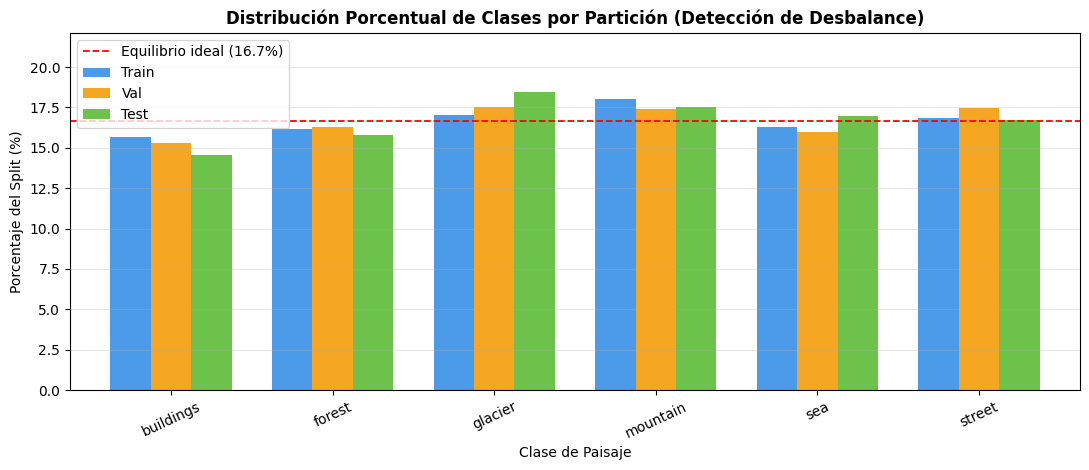

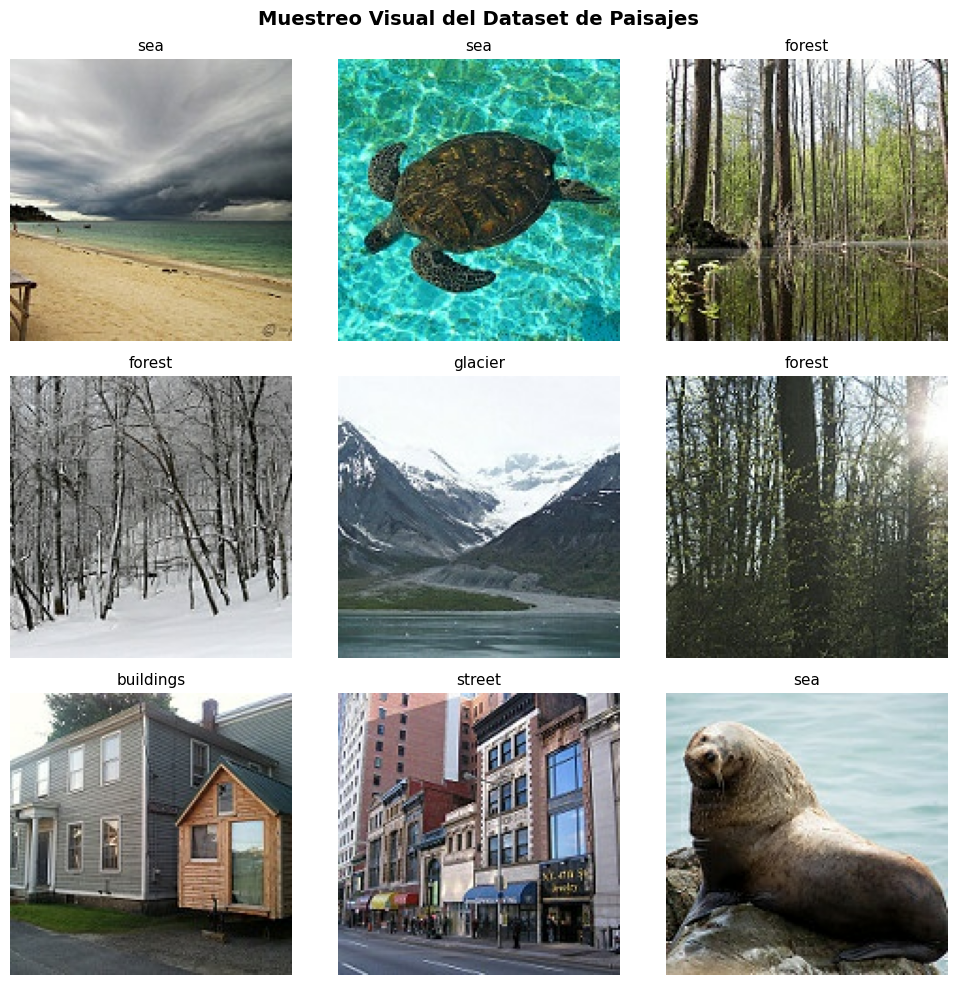


#################################################################
  [FASE 1] EJECUTANDO: 01_Baseline_E2
#################################################################
Epoch 1/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 36s 71ms/step - accuracy: 0.6168 - loss: 1.0127 - val_accuracy: 0.7099 - val_loss: 0.7242
Epoch 2/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.7436 - loss: 0.6863 - val_accuracy: 0.7912 - val_loss: 0.5696
Epoch 3/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.8229 - loss: 0.4978 - val_accuracy: 0.7844 - val_loss: 0.5746
Epoch 4/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.8771 - loss: 0.3530 - val_accuracy: 0.7855 - val_loss: 0.6272
Epoch 5/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.8988 - loss: 0.2786 - val_accuracy: 0.7117 - val_loss: 0.9899
Epoch 6/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.9251 - loss: 0.2116 - val_accuracy: 0.7755 - val_loss: 0.8952
Epoch 7/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step -

In [ ]:
ctx = ejecutar_pipeline_completo(forzar_reinicio=False)

---
## 4. Visualización de ejecución etapas 1 a 3: Carga, EDA (Balance de Clases) y Preprocesamiento

Se cargan las particiones `train`, `val` y `test` una sola vez, se audita el equilibrio de clases (*Ratio Max/Min*) para descartar sesgos de muestreo y se normalizan los píxeles a `[0, 1]`.

In [ ]:
# ==============================================================================
# EXTRACCIÓN DESDE PIPELINE: CARGA, EDA / BALANCE DE CLASES Y PREPROCESAMIENTO
# ==============================================================================
class_names = ctx["class_names"]
df_balance = ctx["df_balance"]
train_ds = ctx["train_ds"]
val_ds = ctx["val_ds"]
test_ds = ctx["test_ds"]

NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}): {class_names}")

# Mostrar tabla de balance de clases calculada en la Etapa 2
display(df_balance)

print("[OK] Datasets preprocesados y recuperados desde el contexto del pipeline.")

Clases (6): ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


,Train,Val,Test,Total
buildings,1761,430,437,2628
forest,1814,457,474,2745
glacier,1912,492,553,2957
mountain,2023,489,525,3037
sea,1826,448,510,2784
street,1892,490,501,2883


[OK] Datasets preprocesados y recuperados desde el contexto del pipeline.


### Validación Visual del Data Augmentation (Transformaciones Físicamente Válidas)
Se aplican únicamente `RandomFlip("horizontal")`, `RandomRotation(0.03)` (±10.8°) y `RandomZoom(0.1)` (±10%), descartando *flip vertical* o rotaciones extremas que invertirían el horizonte natural de los paisajes.

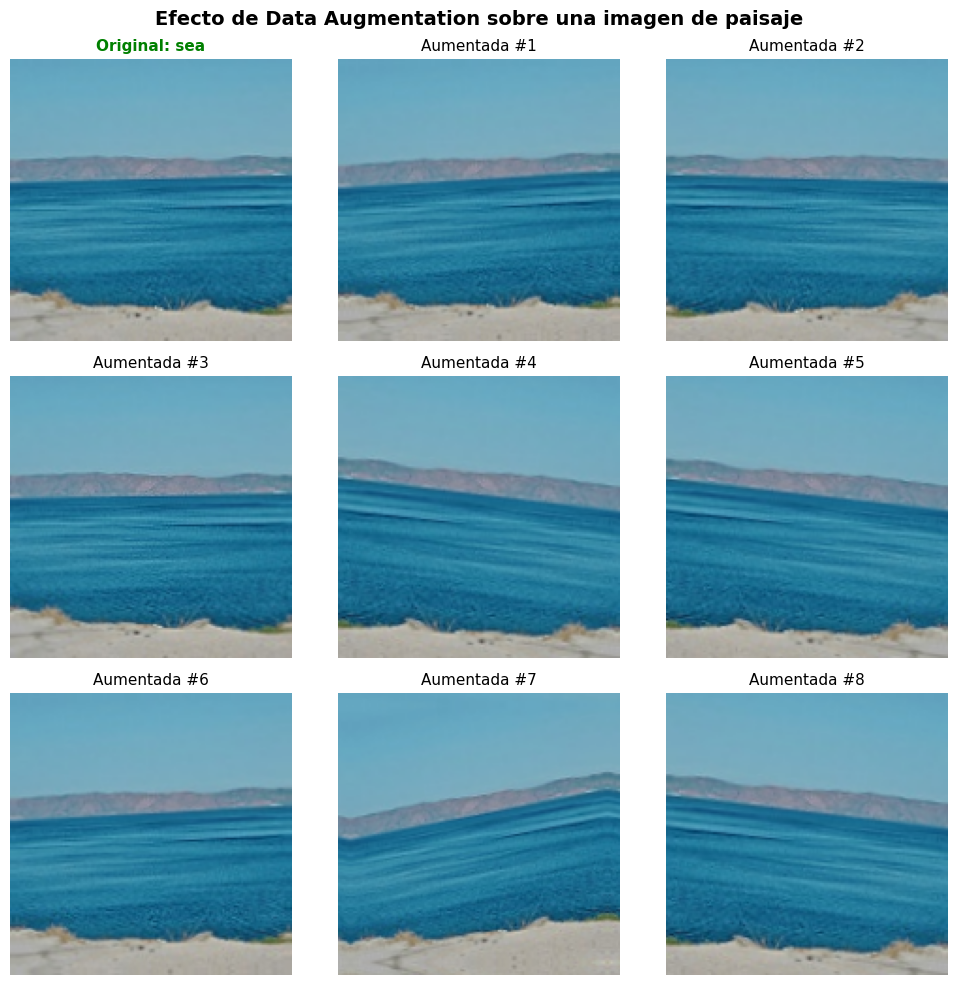

In [ ]:
# ============================================================================
# Visualización del efecto de Data Augmentation
# ============================================================================
data_aug_preview = crear_capa_augmentation(seed=SEED)

# Tomar una imagen del dataset y mostrar 9 versiones aumentadas
for images, labels in train_ds.take(1):
    img_original = images[0]
    clase = class_names[np.argmax(labels[0].numpy())]
    break

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for i in range(9):
    ax = axes[i // 3, i % 3]
    augmented = data_aug_preview(tf.expand_dims(img_original, 0), training=True)
    ax.imshow((augmented[0].numpy() * 255).astype("uint8"))
    if i == 0:
        ax.set_title(f"Original: {clase}", fontsize=11, color="green", fontweight="bold")
    else:
        ax.set_title(f"Aumentada #{i}", fontsize=11)
    ax.axis("off")
plt.suptitle("Efecto de Data Augmentation sobre una imagen de paisaje",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

---
## 5. Experimentación Sistemática de Regularización (Catálogo en 3 Fases)

Se ejecutan de forma modular y reproducible los **14 experimentos de regularización** organizados en 3 fases progresivas mediante `ejecutar_catalogo_regularizacion()`:
* **Fase 1 (`Exp. 01–07`):** Línea Base E2 y evaluación aislada de cada técnica (*Data Augmentation, Batch Normalization, Dropout 0.4, Early Stopping, L2 Ridge, L1 Lasso*).
* **Fase 2 (`Exp. 08–11`):** Combinaciones progresivas de técnicas para estudiar sinergias e interferencias (ej. interacción *BatchNorm + Dropout + DA*).
* **Fase 3 (`Exp. 12–14`):** Calibración fina sin *Batch Normalization* (`Dropout 0.3 / 0.5`, `L2 leve`, `patience 5 / 6`).

La selección y ordenamiento se realiza por **`Val_Loss` (criterio libre de fuga de datos)**, guardando automáticamente checkpoints en `/content/pipeline_artifacts/`.

In [ ]:
# ==============================================================================
# VISUALIZACIÓN ETAPAS 4-6: RESULTADOS DEL CATÁLOGO DE REGULARIZACIÓN
# ==============================================================================
df_reg = ctx["df_reg"]
all_results = ctx["all_results"]
all_histories = ctx["all_histories"]
mejor_reg = ctx["mejor_reg"]

print("Resumen comparativo del Catálogo de Regularización (ordenado por Val_Loss):")
display(df_reg)

print(f"\n[MEJOR] Experimento ganador: {mejor_reg}")


Resumen comparativo del Catálogo de Regularización (ordenado por Val_Loss):


,Fase,Experimento,Val_Loss,Val_Acc,Train_Acc,Brecha_%,Test_Acc,Precision,Recall,Test_F1,Epocas,Tiempo_s,Parametros
0,3,13_Variante_DA_Drop0.5_ES,0.4333,0.8453,0.8557,1.04,0.8430,0.8442,0.8430,0.8425,18,177.56,4829126
1,3,14_Optimo_DA_Drop0.3_ES_p6,0.4568,0.8425,0.8304,-1.21,0.8367,0.8366,0.8367,0.8349,12,119.64,4829126
2,3,12_Calibrado_DA_Drop0.3_L2leve_ES,0.4745,0.8378,0.8327,-0.51,0.8287,0.8326,0.8287,0.8284,12,121.73,4829126
3,2,09_DA_Dropout0.4_ES,0.5063,0.8207,0.7863,-3.44,0.8160,0.8173,0.8160,0.8150,12,118.64,4829126
4,2,08_DA_ES,0.5249,0.8125,0.8493,3.68,0.8077,0.8114,0.8077,0.8055,11,109.68,4829126
5,1,05_Solo_EarlyStopping,0.5550,0.7912,0.7553,-3.59,0.7840,0.7906,0.7840,0.7847,7,68.27,4829126
6,1,02_Solo_DA,0.7012,0.7940,0.9043,11.03,0.7913,0.8071,0.7913,0.7898,10,103.49,4829126
7,1,04_Solo_Dropout_0.4,0.7616,0.8043,0.9308,12.65,0.8070,0.8143,0.8070,0.8063,10,93.75,4829126
8,1,07_Solo_L1_1e-4,0.7736,0.7990,0.8435,4.45,0.7763,0.7897,0.7763,0.7747,10,96.31,4829126
9,1,06_Solo_L2_1e-3,0.7842,0.8068,0.8997,9.29,0.8043,0.8129,0.8043,0.8044,10,95.26,4829126



[MEJOR] Experimento ganador: 13_Variante_DA_Drop0.5_ES


### Comparación de Curvas de Validación de los 14 Experimentos

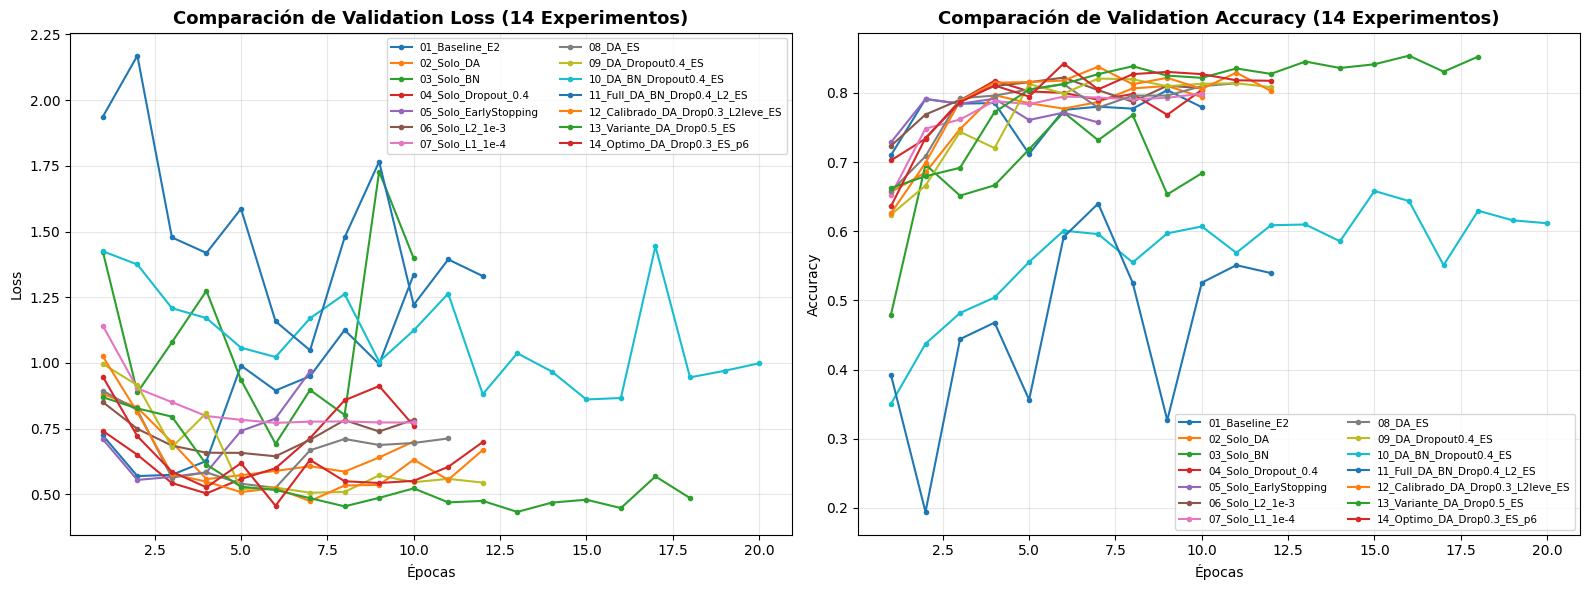

In [ ]:
# ==============================================================================
# CURVAS DE VALIDACIÓN SUPERPUESTAS (LOS 14 EXPERIMENTOS DEL CATÁLOGO)
# ==============================================================================
fig, axs = plt.subplots(1, 2, figsize=(16, 6))
for name, hist in all_histories.items():
    epochs_r = range(1, len(hist["val_loss"]) + 1)
    axs[0].plot(epochs_r, hist["val_loss"], marker="o", markersize=3, label=name)
    axs[1].plot(epochs_r, hist["val_accuracy"], marker="o", markersize=3, label=name)

axs[0].set_title("Comparación de Validation Loss (14 Experimentos)", fontsize=13, fontweight="bold")
axs[0].set_xlabel("Épocas"); axs[0].set_ylabel("Loss")
axs[0].grid(True, alpha=0.3); axs[0].legend(fontsize=7.5, ncol=2)

axs[1].set_title("Comparación de Validation Accuracy (14 Experimentos)", fontsize=13, fontweight="bold")
axs[1].set_xlabel("Épocas"); axs[1].set_ylabel("Accuracy")
axs[1].grid(True, alpha=0.3); axs[1].legend(fontsize=7.5, ncol=2)

plt.tight_layout()
plt.show()

### Síntesis Experimental de las Técnicas de Regularización
* **Combinación ganadora (`Data Augmentation + Dropout + Early Stopping`, sin `BatchNorm`):** Lidera el ranking en `Val_Loss`, `Test_Acc` y menor brecha de sobreajuste. `Data Augmentation` incrementa la diversidad espacial, `Dropout` frena la co-adaptación en la capa `Dense(128)` (que concentra el 98% de los parámetros) y `Early Stopping` restaura los pesos exactamente antes de que `Val_Loss` diverja.
* **Por qué se descarta `Batch Normalization` en combinación con `DA + Dropout`:** En las Fases 2 y 3 se evidencia que introducir `BatchNormalization` junto a *Data Augmentation* y *Dropout* provoca inestabilidad en las estadísticas de los mini-batches (*variance shift*), duplicando el tiempo por época y degradando consistentemente el desempeño en validación y prueba.

---
## 6. Etapa 9: Optimización Controlada de Hiperparámetros y Evaluación Probabilística (ROC-AUC)

Partiendo de la familia ganadora de regularización (`Data Augmentation + Dropout + Early Stopping`, sin `BatchNorm`), se ejecuta una **búsqueda controlada variando un hiperparámetro a la vez** respecto a la configuración base:
1. **Config 0 (Base Regularizada):** `lr = 0.001`, `dropout = 0.5`, `neuronas = 128`.
2. **Config 1 (Learning Rate fino):** `lr = 0.0005` *(evalúa convergencia más suave)*.
3. **Config 2 (Dropout moderado):** `dropout = 0.4` *(evalúa menor apagado neuronal)*.
4. **Config 3 (Mayor capacidad densa):** `neuronas = 256` *(evalúa mayor capacidad en el clasificador frente a su costo de parámetros)*.

#### Tabla y curvas de las 4 configuraciones de hiperparámetros

Configuración ganadora: 1. LR Fino (lr=0.0005, drop=0.5, dense=128)


,nombre,learning_rate,dropout_rate,neuronas,Val_Loss,Val_Acc,Train_Acc,Brecha_%,Test_Acc,Precision,Recall,Test_F1,Epocas,Parametros,Tiempo_s,Tiempo_Epoca_s
0,"1. LR Fino (lr=0.0005, drop=0.5, dense=128)",0.0005,0.5,128,0.4608,0.8411,0.8553,1.42,0.8420,0.8441,0.8420,0.8415,18,4829126,181.47,10.08
1,"3. Densa Mayor (lr=0.001, drop=0.5, dense=256)",0.0010,0.5,256,0.4916,0.8225,0.8603,3.78,0.8160,0.8253,0.8160,0.8156,15,9564998,194.28,12.95
2,"2. Drop Moderado (lr=0.001, drop=0.4, dense=128)",0.0010,0.4,128,0.4917,0.8282,0.8470,1.88,0.8270,0.8291,0.8270,0.8260,15,4829126,152.23,10.15
3,"0. Base Reg (lr=0.001, drop=0.5, dense=128)",0.0010,0.5,128,0.5080,0.8158,0.7741,-4.17,0.8033,0.8055,0.8033,0.8018,10,4829126,99.48,9.95


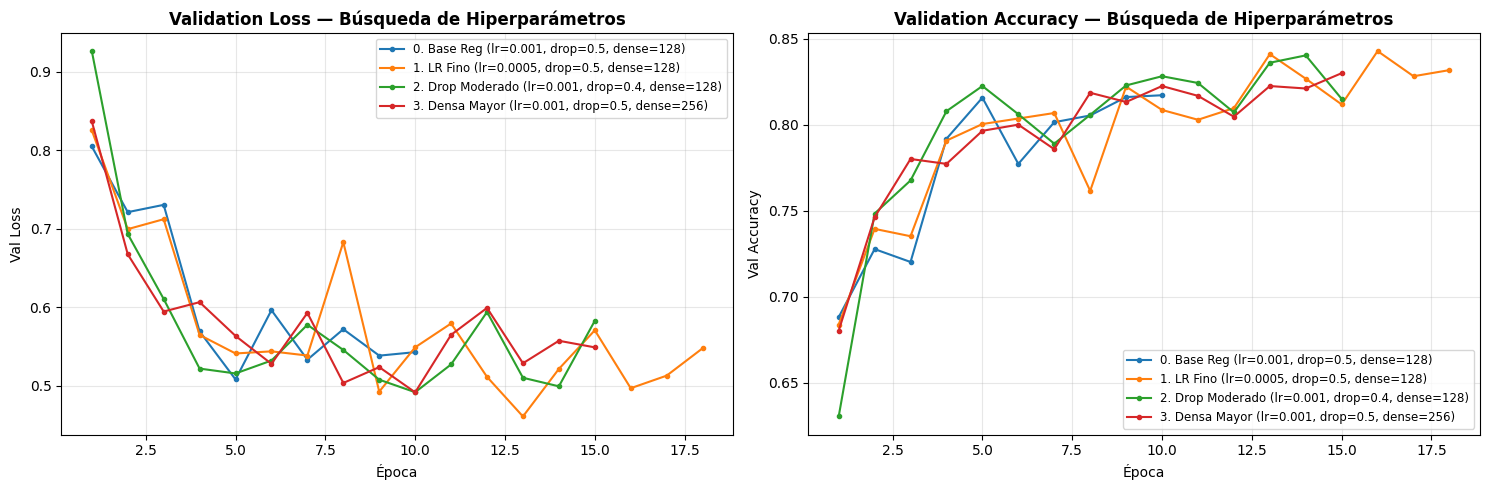

In [ ]:
# ==============================================================================
# VISUALIZACIÓN: OPTIMIZACIÓN CONTROLADA DE HIPERPARÁMETROS
# ==============================================================================
df_opt = ctx["df_opt"]
mejor_cfg = ctx["mejor_cfg"]
best_res = ctx["best_res"]
best_hist = ctx["best_hist"]
hist_opt = ctx["hist_opt"]

print(f"Configuración ganadora: {mejor_cfg['nombre']}")
display(df_opt)

# Gráfico comparativo de curvas de validación de las 4 configuraciones
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
for nombre, h in hist_opt.items():
    ep = range(1, len(h["val_loss"]) + 1)
    axs[0].plot(ep, h["val_loss"], marker="o", ms=3, label=nombre)
    axs[1].plot(ep, h["val_accuracy"], marker="o", ms=3, label=nombre)

axs[0].set_title("Validation Loss — Búsqueda de Hiperparámetros", fontweight="bold")
axs[0].set_xlabel("Época"); axs[0].set_ylabel("Val Loss")
axs[0].grid(True, alpha=0.3); axs[0].legend(fontsize=8.5)

axs[1].set_title("Validation Accuracy — Búsqueda de Hiperparámetros", fontweight="bold")
axs[1].set_xlabel("Época"); axs[1].set_ylabel("Val Accuracy")
axs[1].grid(True, alpha=0.3); axs[1].legend(fontsize=8.5)

plt.tight_layout()
plt.show()

#### Evaluación integral y ROC-AUC del modelo ganador


=== REPORTE DE CLASIFICACIÓN: MODELO FINAL (1. LR Fino (lr=0.0005, drop=0.5, dense=128)) ===
              precision    recall  f1-score   support

   buildings     0.8820    0.7529    0.8123       437
      forest     0.9402    0.9620    0.9510       474
     glacier     0.8208    0.7866    0.8033       553
    mountain     0.7640    0.8324    0.7967       525
         sea     0.8560    0.8157    0.8353       510
      street     0.8177    0.9042    0.8588       501

    accuracy                         0.8420      3000
   macro avg     0.8468    0.8423    0.8429      3000
weighted avg     0.8441    0.8420    0.8415      3000



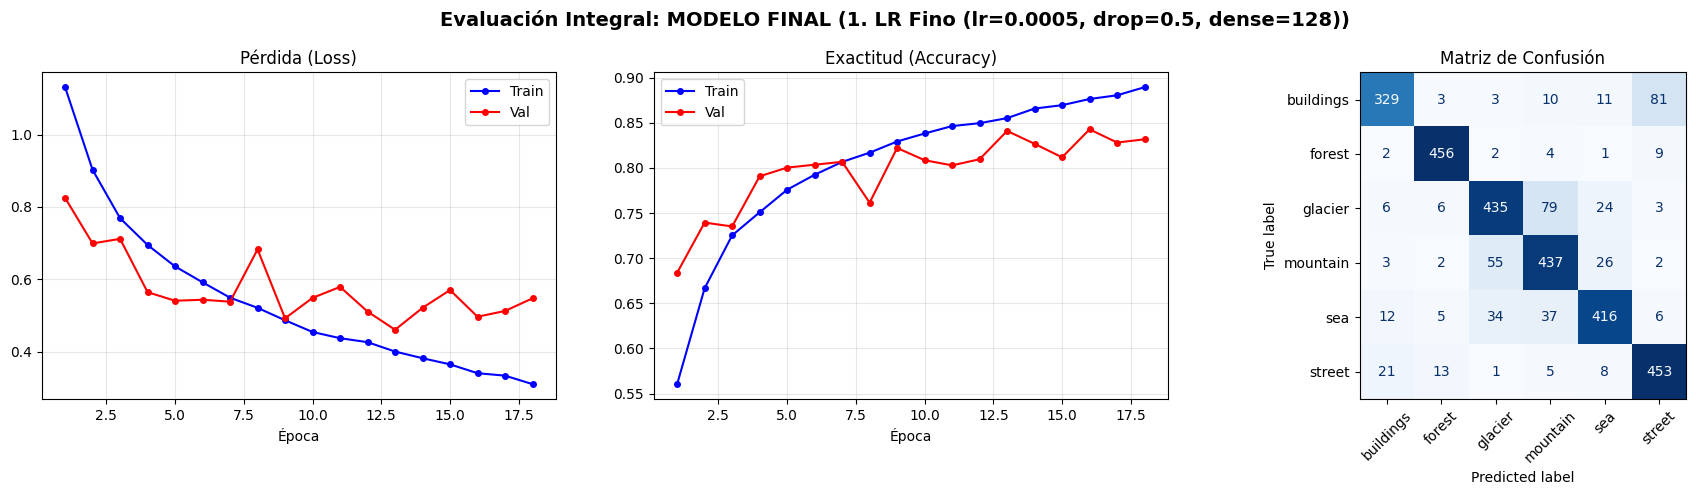


  ROC-AUC (OvR): MODELO FINAL (1. LR Fino (lr=0.0005, drop=0.5, dense=128))
  Macro: 0.9770 | Weighted: 0.9765
--------------------------------------------------------
    • buildings : AUC = 0.9741
    • forest    : AUC = 0.9983
    • glacier   : AUC = 0.9631
    • mountain  : AUC = 0.9676
    • sea       : AUC = 0.9760
    • street    : AUC = 0.9828


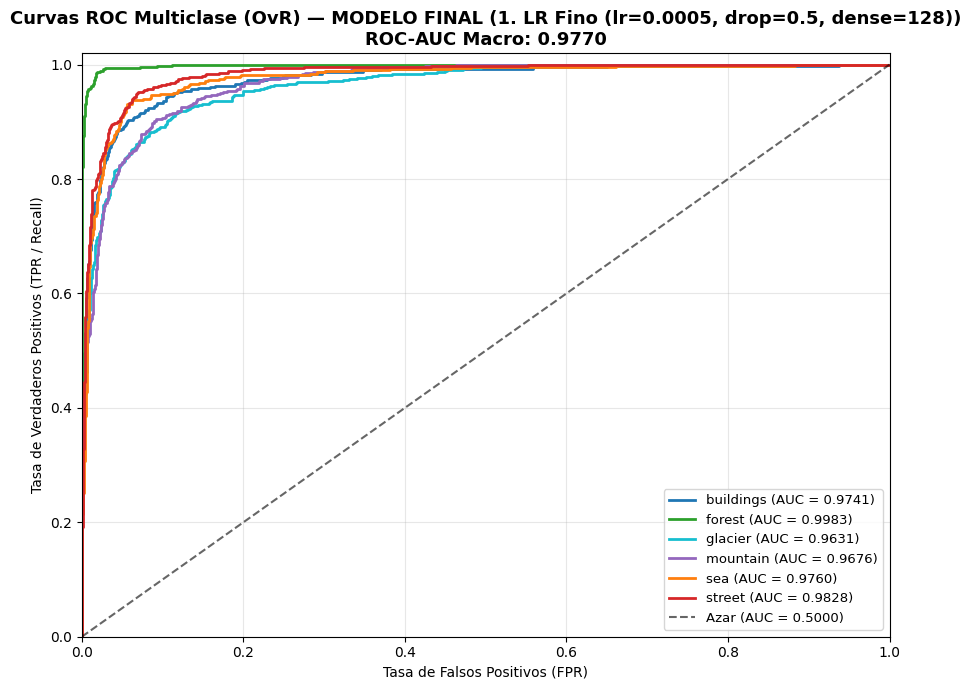

In [ ]:
# ==============================================================================
# EVALUACIÓN INTEGRAL Y CURVAS ROC-AUC (ONE-VS-REST) DEL MODELO GANADOR
# ==============================================================================
mejor_modelo = ctx["mejor_modelo"]
test_ds = ctx["test_ds"]
class_names = ctx["class_names"]
nombre_ganador = mejor_cfg["nombre"]

eval_final = evaluar_modelo(
    mejor_modelo, test_ds, class_names,
    f"MODELO FINAL ({nombre_ganador})",
    history_dict=best_hist, plot=True
)
roc_final = evaluate_roc_auc(
    mejor_modelo, test_ds, class_names,
    f"MODELO FINAL ({nombre_ganador})", plot=True
)

### Análisis Crítico de la Optimización de Hiperparámetros y ROC-AUC
1. **Selección del Modelo Final (`1. LR Fino: lr=0.0005, drop=0.5, dense=128`):** La tabla `df_opt` demuestra que reducir la tasa de aprendizaje a `0.0005` manteniendo `Dropout(0.5)` y `Dense(128)` logró la menor pérdida de validación (**`Val_Loss = 0.4608`**) y el mejor desempeño global en prueba (**`Accuracy = 84.20%`**, **`F1-Score = 0.8415`**, **`ROC-AUC Macro = 0.9770`**), con una brecha de sobreajuste mínima (**`1.42%`**) en `18` épocas (`181.47 s`, `10.08 s/época`). Además, conserva una arquitectura compacta de **`4,829,126` parámetros** (un **44.2% menos** que los `8.65M` del MLP Base), evitando el sobreajuste observado al duplicar la capa densa a `256` neuronas (`3. Densa Mayor`: `Val_Loss = 0.4916`, `Brecha = 3.78%`, `9.56M` parámetros).
2. **Efecto del *Learning Rate* y del *Dropout*:** Variar un parámetro a la vez mostró que un paso de actualización más fino (`lr = 0.0005`) permite que `Adam` converja de manera más estable bajo la regularización estocástica de *Data Augmentation* + `Dropout(0.5)` (+3.87 puntos sobre `0. Base Reg` con `lr = 0.001`), mientras que reducir el apagado neuronal a `Dropout(0.4)` (`2. Drop Moderado`) incrementa ligeramente el sobreajuste (`Val_Loss = 0.4917`, `Accuracy = 82.70%`).
3. **Interpretación de las curvas ROC-AUC (One-vs-Rest):** El área bajo la curva (**`ROC-AUC Macro = 0.9770`** | **`Weighted = 0.9765`**) confirma una sólida capacidad discriminativa probabilística en las seis categorías: `forest` (`0.9983`), `street` (`0.9828`), `sea` (`0.9760`), `buildings` (`0.9741`), `mountain` (`0.9676`) y `glacier` (`0.9631`), evidenciando que el mayor solapamiento visual ocurre entre `glacier` y `mountain`.

---
## 7. Comparación Integral de Arquitecturas: MLP (Ev. 1) vs. CNN Base (Ev. 2) vs. CNN Final Optimizada (Ev. 3)

Siguiendo las indicaciones de la asignatura, el **MLP de la Entrega 1 se mantiene fijo** como línea base clásica (no se re-optimiza porque su limitación es estructural: la capa `Flatten` destruye la topología espacial 2D y dispara los parámetros a **8.65 millones**). A continuación se contrastan dinámicamente los **3 hitos evolutivos del proyecto** sobre `test_ds`, enfrentando la línea base MLP y la CNN sin regularizar contra el **modelo final optimizado seleccionado en la Sección 6** (`mejor_cfg_e3`).

In [ ]:
# ==============================================================================
# COMPARACIÓN EVOLUTIVA DE HITOS: E1 vs E2 vs E3
# ==============================================================================
fila_cnn_e2 = ctx["df_reg"].loc[ctx["df_reg"]["Experimento"] == "01_Baseline_E2"].iloc[0]
best_res = ctx["best_res"]

df_hitos = pd.DataFrame([
    METRICAS_MLP_E1,
    {
        "Modelo": "CNN Base (Ev. 2)",
        "Accuracy": fila_cnn_e2["Test_Acc"],
        "Precision": fila_cnn_e2["Precision"],
        "Recall": fila_cnn_e2["Recall"],
        "F1_Score": fila_cnn_e2["Test_F1"],
        "Train_Acc": fila_cnn_e2["Train_Acc"],
        "Val_Acc": fila_cnn_e2["Val_Acc"],
        "Val_Loss": fila_cnn_e2["Val_Loss"],
        "Brecha_Overfitting_%": fila_cnn_e2["Brecha_%"],
        "Parametros": fila_cnn_e2["Parametros"],
        "Tiempo_Total_s": fila_cnn_e2["Tiempo_s"],
        "Tiempo_Epoca_s": round(fila_cnn_e2["Tiempo_s"] / max(fila_cnn_e2["Epocas"], 1), 2),
    },
    {
        "Modelo": "CNN Final (Ev. 3)",
        "Accuracy": best_res["Test_Acc"],
        "Precision": best_res["Precision"],
        "Recall": best_res["Recall"],
        "F1_Score": best_res["Test_F1"],
        "Train_Acc": best_res["Train_Acc"],
        "Val_Acc": best_res["Val_Acc"],
        "Val_Loss": best_res["Val_Loss"],
        "Brecha_Overfitting_%": best_res["Brecha_%"],
        "Parametros": best_res["Parametros"],
        "Tiempo_Total_s": best_res["Tiempo_s"],
        "Tiempo_Epoca_s": best_res["Tiempo_Epoca_s"],
    }
])

display(df_hitos)

,Modelo,Accuracy,Precision,Recall,F1_Score,Train_Acc,Val_Acc,Val_Loss,Brecha_Overfitting_%,Parametros,Tiempo_Total_s,Tiempo_Epoca_s
0,MLP Base (Ev. 1),0.5437,0.5480,0.5437,0.5410,0.5650,0.5437,1.3200,2.13,8648774,42.40,4.24
1,CNN Base (Ev. 2),0.7847,0.7991,0.7847,0.7838,0.9816,0.7794,1.3363,20.22,4829126,114.32,11.43
2,CNN Final (Ev. 3),0.8420,0.8441,0.8420,0.8415,0.8553,0.8411,0.4608,1.42,4829126,181.47,10.08


### Comparación Histórica (Antes de Regularizar): MLP (Ev. 1) vs. CNN Base (Ev. 2)
Contraste directo entre la red densa clásica (entrada aplanada 1D) y la CNN pura sin regularización. Se evidencia por qué fue obligatorio regularizar en la Evaluación 3: aunque la CNN supera ampliamente al MLP en acierto y usa **44.2% menos parámetros**, presenta un **sobreajuste severo** entre entrenamiento y validación.

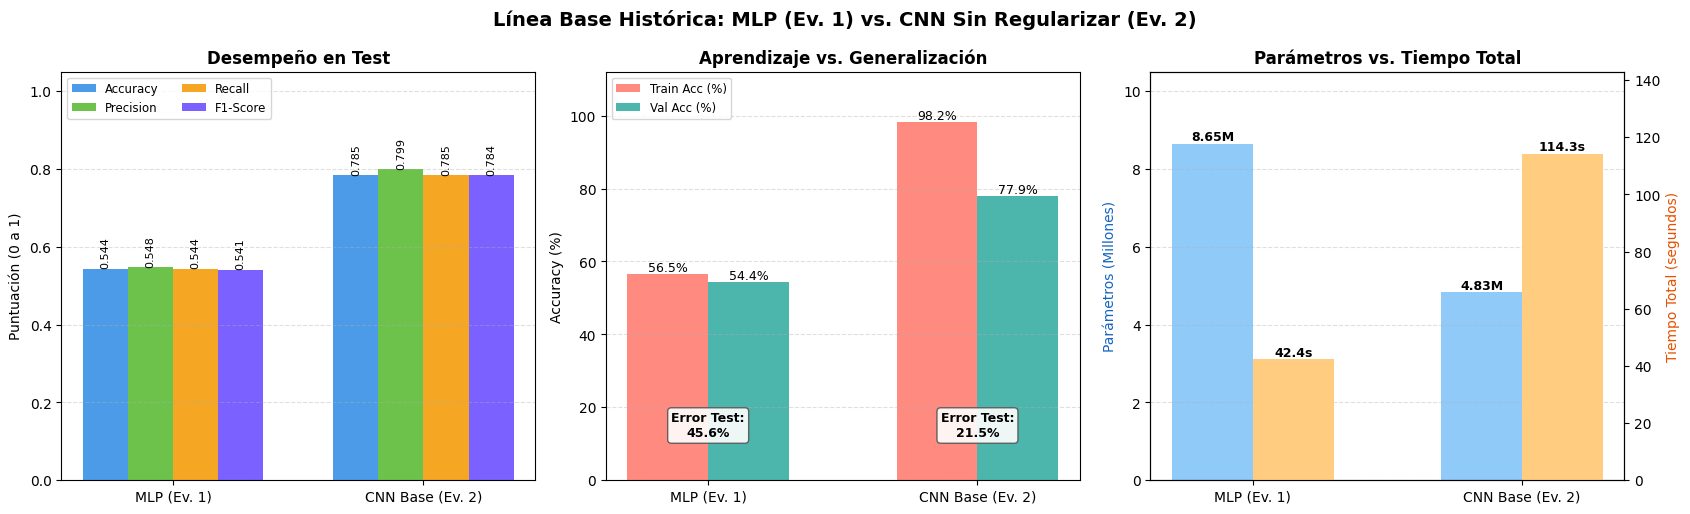

In [ ]:
# ==============================================================================
# GRÁFICO HISTÓRICO (ANTES DE REGULARIZAR): MLP (Ev. 1) vs. CNN BASE (Ev. 2)
# Reutiliza directamente las primeras 2 filas de `df_hitos` (sin duplicar datos).
# ==============================================================================
df_e2 = df_hitos.iloc[:2].copy()
df_e2["Modelo_Corto"] = ["MLP (Ev. 1)", "CNN Base (Ev. 2)"]
df_e2["Error_%"] = (1 - df_e2["Accuracy"]) * 100
df_e2["Parametros_M"] = df_e2["Parametros"] / 1e6

fig, axs = plt.subplots(1, 3, figsize=(17, 5.2))
mods = df_e2["Modelo_Corto"].tolist()
x = np.arange(len(mods))

# 1. Desempeño en Test (4 métricas)
w = 0.18
for idx, (col, color) in enumerate([("Accuracy", "#4C9BE8"), ("Precision", "#6CC24A"), ("Recall", "#F5A623"), ("F1_Score", "#7B61FF")]):
    bars = axs[0].bar(x + (idx - 1.5) * w, df_e2[col], w, label=col.replace("_", "-"), color=color)
    for b in bars:
        axs[0].annotate(f"{b.get_height():.3f}", (b.get_x() + b.get_width()/2, b.get_height()), ha="center", va="bottom", fontsize=8, rotation=90)
axs[0].set_title("Desempeño en Test", fontweight="bold")
axs[0].set_ylabel("Puntuación (0 a 1)")
axs[0].set_xticks(x); axs[0].set_xticklabels(mods)
axs[0].set_ylim(0, 1.05); axs[0].grid(axis="y", linestyle="--", alpha=0.4)
axs[0].legend(loc="upper left", ncol=2, fontsize=8.5)

# 2. Subajuste (MLP) vs. Sobreajuste (CNN Base)
w2 = 0.30
axs[1].bar(x - w2/2, df_e2["Train_Acc"] * 100, w2, label="Train Acc (%)", color="#FF8A80")
axs[1].bar(x + w2/2, df_e2["Val_Acc"] * 100, w2, label="Val Acc (%)", color="#4DB6AC")
for i in range(len(x)):
    axs[1].annotate(f"{df_e2['Train_Acc'].iloc[i]*100:.1f}%", (x[i] - w2/2, df_e2["Train_Acc"].iloc[i]*100), ha="center", va="bottom", fontsize=9)
    axs[1].annotate(f"{df_e2['Val_Acc'].iloc[i]*100:.1f}%", (x[i] + w2/2, df_e2["Val_Acc"].iloc[i]*100), ha="center", va="bottom", fontsize=9)
    axs[1].text(x[i], 12, f"Error Test:\n{df_e2['Error_%'].iloc[i]:.1f}%", ha="center", fontsize=9, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#555", alpha=0.9))
axs[1].set_title("Aprendizaje vs. Generalización", fontweight="bold")
axs[1].set_ylabel("Accuracy (%)")
axs[1].set_xticks(x); axs[1].set_xticklabels(mods)
axs[1].set_ylim(0, 112); axs[1].grid(axis="y", linestyle="--", alpha=0.4)
axs[1].legend(loc="upper left", fontsize=8.5)

# 3. Complejidad (Parámetros) vs. Tiempo Total
axs[2].bar(x - w2/2, df_e2["Parametros_M"], w2, color="#90CAF9")
for i, v in enumerate(df_e2["Parametros_M"]):
    axs[2].annotate(f"{v:.2f}M", (x[i] - w2/2, v), ha="center", va="bottom", fontsize=9, fontweight="bold")
axs[2].set_ylabel("Parámetros (Millones)", color="#1565C0")
axs[2].set_ylim(0, 10.5); axs[2].set_xticks(x); axs[2].set_xticklabels(mods)
axs[2].grid(axis="y", linestyle="--", alpha=0.4)

ax_t = axs[2].twinx()
ax_t.bar(x + w2/2, df_e2["Tiempo_Total_s"], w2, color="#FFCC80")
for i, v in enumerate(df_e2["Tiempo_Total_s"]):
    ax_t.annotate(f"{v:.1f}s", (x[i] + w2/2, v), ha="center", va="bottom", fontsize=9, fontweight="bold")
ax_t.set_ylabel("Tiempo Total (segundos)", color="#E65100")
ax_t.set_ylim(0, max(df_e2["Tiempo_Total_s"]) * 1.25)
axs[2].set_title("Parámetros vs. Tiempo Total", fontweight="bold")

plt.suptitle("Línea Base Histórica: MLP (Ev. 1) vs. CNN Sin Regularizar (Ev. 2)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("comparacion_mlp_vs_cnn_base.png", dpi=150, bbox_inches="tight")
plt.show()

### Evolución Completa: MLP (Ev. 1) vs. CNN Base (Ev. 2) vs. CNN Final Optimizada (Ev. 3)
A continuación se visualiza el impacto integral de la arquitectura convolucional, la regularización y la optimización final en las cuatro dimensiones exigidas por la rúbrica: desempeño en test, generalización (brecha de sobreajuste y `Val Loss`), complejidad de parámetros (`8.65M` en MLP vs. `4.83M` en CNN Base y `9.56M` en la CNN Final `Dense(256)`) y costo computacional.

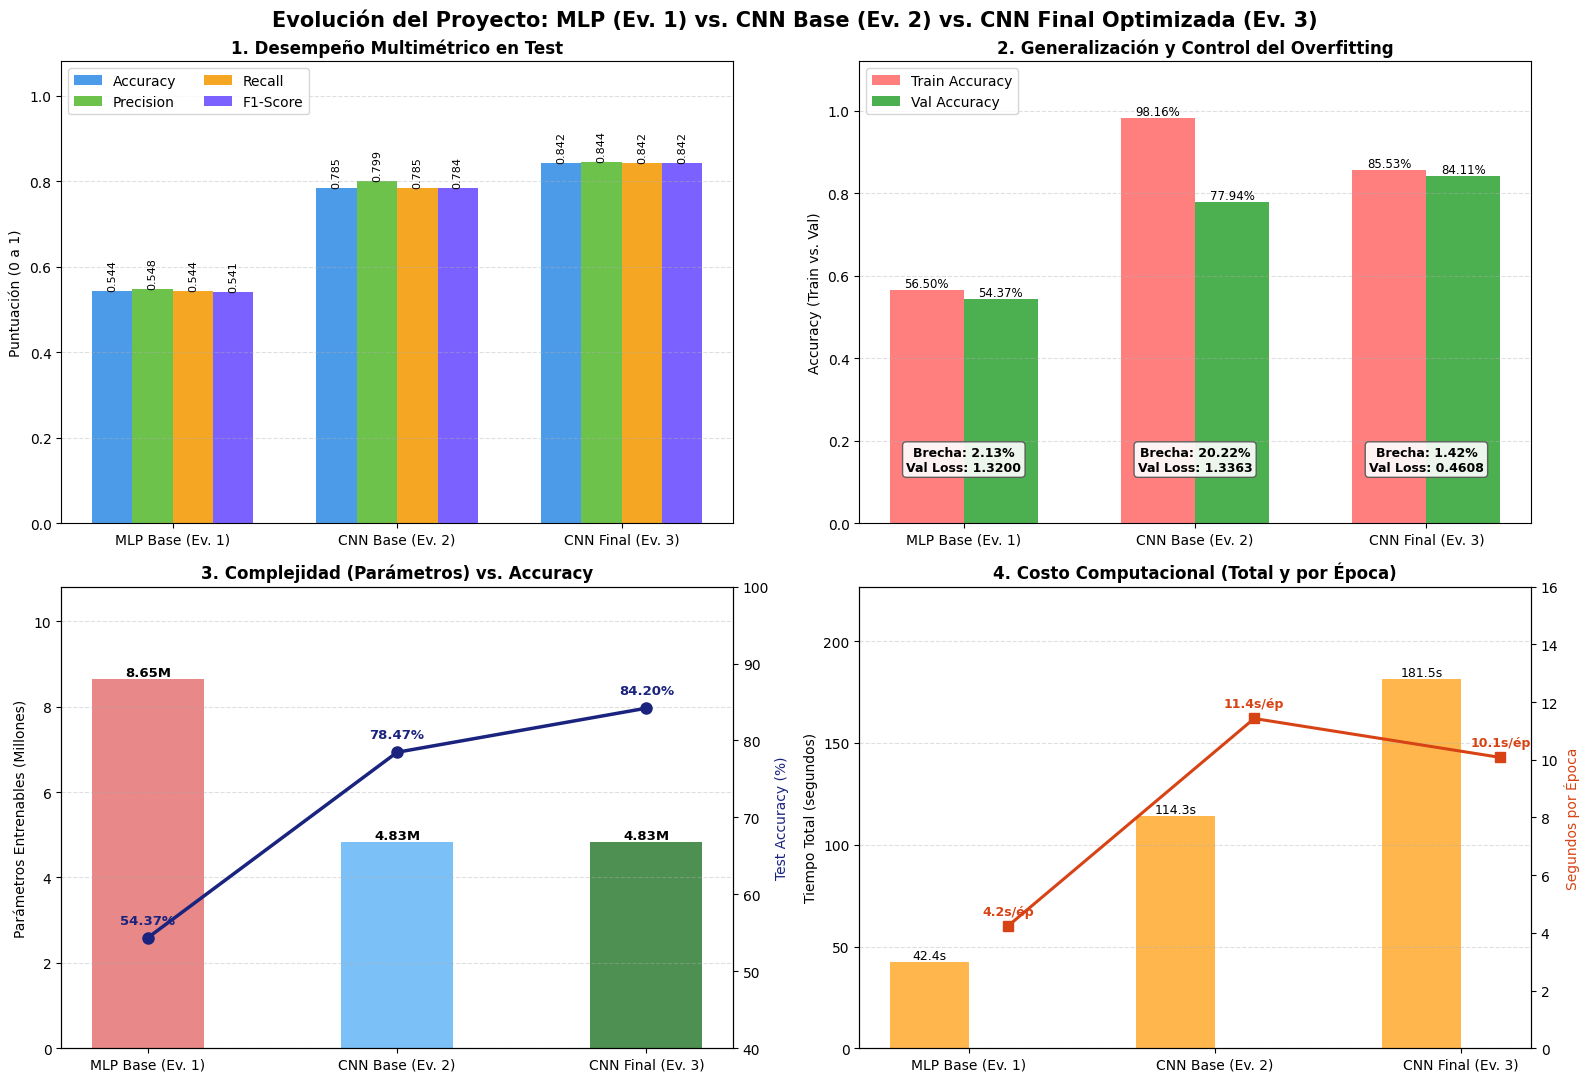

In [ ]:
# ==============================================================================
# COMPARACIÓN INTEGRAL (MLP vs. CNN BASE vs. CNN GANADORA)
# ==============================================================================
fig, axs = plt.subplots(2, 2, figsize=(16, 11))
modelos = df_hitos["Modelo"].tolist()
x = np.arange(len(modelos))

# 1. Desempeño Multimétrico en Test
w = 0.18
for idx, (col, color) in enumerate([("Accuracy", "#4C9BE8"), ("Precision", "#6CC24A"), ("Recall", "#F5A623"), ("F1_Score", "#7B61FF")]):
    bars = axs[0, 0].bar(x + (idx - 1.5) * w, df_hitos[col], w, label=col.replace("_", "-"), color=color)
    for b in bars:
        axs[0, 0].annotate(f"{b.get_height():.3f}", (b.get_x() + b.get_width()/2, b.get_height()), ha="center", va="bottom", fontsize=8, rotation=90)
axs[0, 0].set_title("1. Desempeño Multimétrico en Test", fontweight="bold")
axs[0, 0].set_ylabel("Puntuación (0 a 1)")
axs[0, 0].set_xticks(x); axs[0, 0].set_xticklabels(modelos)
axs[0, 0].set_ylim(0, 1.08); axs[0, 0].grid(axis="y", linestyle="--", alpha=0.4)
axs[0, 0].legend(loc="upper left", ncol=2)

# 2. Generalización y Brecha de Overfitting
w2 = 0.32
axs[0, 1].bar(x - w2/2, df_hitos["Train_Acc"], w2, label="Train Accuracy", color="#FF7F7F")
axs[0, 1].bar(x + w2/2, df_hitos["Val_Acc"], w2, label="Val Accuracy", color="#4CAF50")
for i in range(len(x)):
    axs[0, 1].annotate(f"{df_hitos['Train_Acc'].iloc[i]:.2%}", (x[i] - w2/2, df_hitos["Train_Acc"].iloc[i]), ha="center", va="bottom", fontsize=8.5)
    axs[0, 1].annotate(f"{df_hitos['Val_Acc'].iloc[i]:.2%}", (x[i] + w2/2, df_hitos["Val_Acc"].iloc[i]), ha="center", va="bottom", fontsize=8.5)
    axs[0, 1].text(x[i], 0.12, f"Brecha: {df_hitos['Brecha_Overfitting_%'].iloc[i]:.2f}%\nVal Loss: {df_hitos['Val_Loss'].iloc[i]:.4f}",
                   ha="center", va="bottom", fontsize=9, fontweight="bold",
                   bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#555", alpha=0.9))
axs[0, 1].set_title("2. Generalización y Control del Overfitting", fontweight="bold")
axs[0, 1].set_ylabel("Accuracy (Train vs. Val)")
axs[0, 1].set_xticks(x); axs[0, 1].set_xticklabels(modelos)
axs[0, 1].set_ylim(0, 1.12); axs[0, 1].grid(axis="y", linestyle="--", alpha=0.4)
axs[0, 1].legend(loc="upper left")

# 3. Complejidad (Parámetros) vs. Accuracy
bars_p = axs[1, 0].bar(x, df_hitos["Parametros"] / 1e6, width=0.45, color=["#E57373", "#64B5F6", "#2E7D32"], alpha=0.85)
for b in bars_p:
    axs[1, 0].annotate(f"{b.get_height():.2f}M", (b.get_x() + b.get_width()/2, b.get_height()), ha="center", va="bottom", fontsize=9.5, fontweight="bold")
axs[1, 0].set_title("3. Complejidad (Parámetros) vs. Accuracy", fontweight="bold")
axs[1, 0].set_ylabel("Parámetros Entrenables (Millones)")
axs[1, 0].set_xticks(x); axs[1, 0].set_xticklabels(modelos)
axs[1, 0].set_ylim(0, max(df_hitos["Parametros"] / 1e6) * 1.25); axs[1, 0].grid(axis="y", linestyle="--", alpha=0.4)

ax_acc = axs[1, 0].twinx()
ax_acc.plot(x, df_hitos["Accuracy"] * 100, color="#1A237E", marker="o", linewidth=2.5, markersize=8)
for i, val in enumerate(df_hitos["Accuracy"] * 100):
    ax_acc.annotate(f"{val:.2f}%", (x[i], val), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=9.5, fontweight="bold", color="#1A237E")
ax_acc.set_ylabel("Test Accuracy (%)", color="#1A237E"); ax_acc.set_ylim(40, 100)

# 4. Costo Computacional
w4 = 0.32
b_tt = axs[1, 1].bar(x - w4/2, df_hitos["Tiempo_Total_s"], w4, color="#FFB74D")
for b in b_tt:
    axs[1, 1].annotate(f"{b.get_height():.1f}s", (b.get_x() + b.get_width()/2, b.get_height()), ha="center", va="bottom", fontsize=9)
axs[1, 1].set_title("4. Costo Computacional (Total y por Época)", fontweight="bold")
axs[1, 1].set_ylabel("Tiempo Total (segundos)")
axs[1, 1].set_xticks(x); axs[1, 1].set_xticklabels(modelos)
axs[1, 1].set_ylim(0, max(df_hitos["Tiempo_Total_s"]) * 1.25); axs[1, 1].grid(axis="y", linestyle="--", alpha=0.4)

ax_ep = axs[1, 1].twinx()
ax_ep.plot(x + w4/2, df_hitos["Tiempo_Epoca_s"], color="#D84315", marker="s", linewidth=2.2, markersize=7)
for i, val in enumerate(df_hitos["Tiempo_Epoca_s"]):
    ax_ep.annotate(f"{val:.1f}s/ép", (x[i] + w4/2, val), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, fontweight="bold", color="#D84315")
ax_ep.set_ylabel("Segundos por Época", color="#D84315"); ax_ep.set_ylim(0, max(df_hitos["Tiempo_Epoca_s"]) * 1.4)

plt.suptitle("Evolución del Proyecto: MLP (Ev. 1) vs. CNN Base (Ev. 2) vs. CNN Final Optimizada (Ev. 3)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

### Comparación de Curvas de Aprendizaje (Antes vs. Después de Regularizar)
Al superponer época por época la evolución del entrenamiento, se confirma que la **CNN Base (rojo)** memoriza rápidamente el set de entrenamiento mientras su pérdida de validación (`Val Loss`) diverge hacia arriba. En cambio, la **CNN Regularizada (verde)** mantiene ambas curvas acopladas y se detiene automáticamente en su punto óptimo mediante *Early Stopping*.

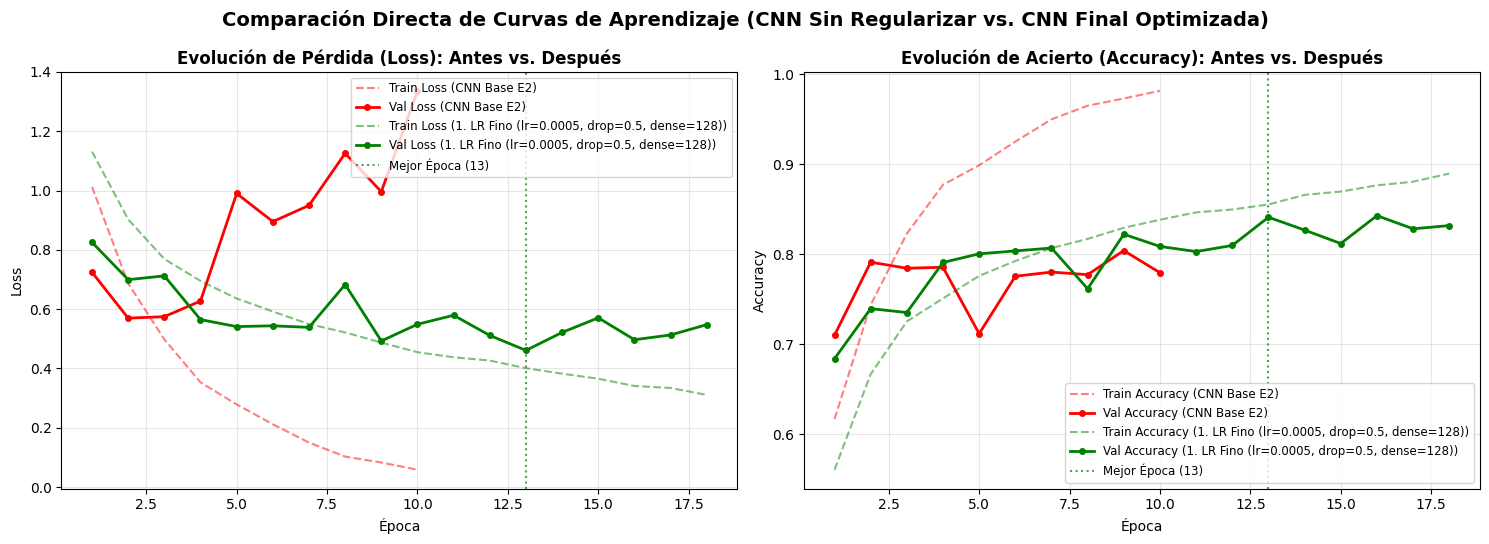

In [ ]:
# ==============================================================================
# CURVAS ÉPOCA POR ÉPOCA — CNN BASE (E2) vs. CNN GANADORA (E3)
# ==============================================================================
hist_base = ctx["all_histories"]["01_Baseline_E2"]
best_key = ctx["mejor_cfg"]["nombre"]
hist_best = ctx["best_hist"]
best_epoch_idx = int(np.argmin(hist_best["val_loss"]))

fig, axs = plt.subplots(1, 2, figsize=(15, 5.5))
ep_base = range(1, len(hist_base["loss"]) + 1)
ep_best = range(1, len(hist_best["loss"]) + 1)

for ax, metrica, titulo in [
    (axs[0], "loss", "Evolución de Pérdida (Loss): Antes vs. Después"),
    (axs[1], "accuracy", "Evolución de Acierto (Accuracy): Antes vs. Después"),
]:
    ax.plot(ep_base, hist_base[metrica], "r--", alpha=0.5, label=f"Train {metrica.title()} (CNN Base E2)")
    ax.plot(ep_base, hist_base[f"val_{metrica}"], "r-o", lw=2, ms=4, label=f"Val {metrica.title()} (CNN Base E2)")
    ax.plot(ep_best, hist_best[metrica], "g--", alpha=0.5, label=f"Train {metrica.title()} ({best_key})")
    ax.plot(ep_best, hist_best[f"val_{metrica}"], "g-o", lw=2, ms=4, label=f"Val {metrica.title()} ({best_key})")
    ax.axvline(best_epoch_idx + 1, color="green", ls=":", alpha=0.7, label=f"Mejor Época ({best_epoch_idx + 1})")
    ax.set_title(titulo, fontweight="bold")
    ax.set_xlabel("Época")
    ax.set_ylabel(metrica.title())
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8.5)

plt.suptitle("Comparación Directa de Curvas de Aprendizaje (CNN Sin Regularizar vs. CNN Final Optimizada)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

---
## 8. Etapa 8: Auditoría del Modelo Final — Explicabilidad (Grad-CAM), Sesgos y Ética

### 8.1 Explicabilidad Visual (Grad-CAM) e Interpretabilidad: MLP vs. CNN
Se aplica **Grad-CAM** sobre la última capa convolucional (`Conv_3`) del modelo final (`mejor_modelo_final.keras`) para visualizar 1 muestra representativa de cada una de las 6 clases y verificar en qué regiones se apoya la red para clasificar.

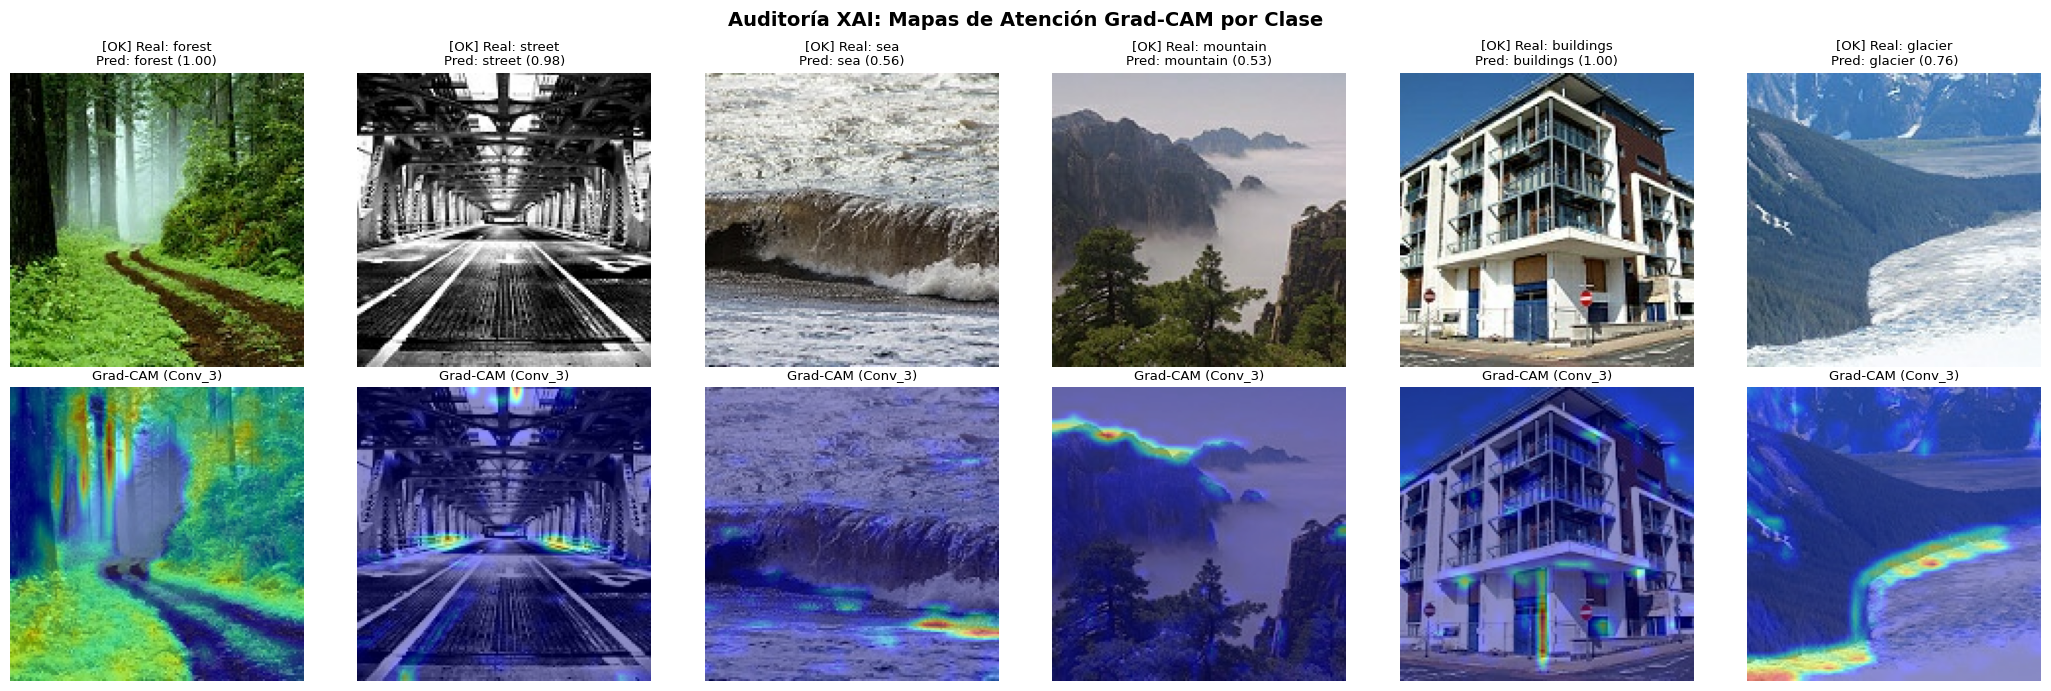

In [ ]:
# ==============================================================================
# AUDITORÍA XAI (GRAD-CAM) SOBRE EL MODELO FINAL (1 EJEMPLO POR CLASE)
# ==============================================================================
gradcam_res = auditar_modelo(
    ctx["mejor_modelo"], ctx["test_ds"], ctx["class_names"],
    input_shape=(*IMG_SIZE, 3), num_samples=6, plot=True
)

### Interpretación de Grad-CAM y Ventaja de Explicabilidad frente al MLP
* **Validación semántica de los mapas de atención:** Los mapas de calor Grad-CAM sobre `Conv_3` confirman que la CNN final acierta las 6 muestras representativas apoyándose en fronteras y texturas físicamente pertinentes: el follaje y troncos en `forest` (`1.00`), la calzada y base estructural en `street` (`0.98`), la fachada geométrica en `buildings` (`1.00`) y el borde brillante del hielo en `glacier` (`0.76`). Incluso en escenas visualmente ambiguas con confianza moderada (como `mountain` (`0.53`), parcialmente cubierta por neblina densa, o `sea` (`0.56`), dominada por una ola rompiendo en primer plano), Grad-CAM demuestra que la red no se distrae con el fondo, sino que localiza exactamente la silueta superior de los picos y la espuma de la rompiente, validando la necesidad de supervisión humana cuando la confianza es inferior a `0.80`.
* **Interpretabilidad CNN vs. MLP:** Mientras que el **MLP** opera como una "caja negra" espacial (al aplanar los `67,500` valores en un vector 1D se pierde la correspondencia directa con regiones de la fotografía), la **CNN** preserva la estructura 2D hasta `Conv_3`, permitiendo auditar cada predicción con **Grad-CAM**. Esta trazabilidad visual es indispensable en el caso de negocio inmobiliario para justificar clasificaciones ante tasadores y clientes.

### 8.2 Auditoría de Sesgos de Predicción, Pares de Confusión y Errores de Alta Confianza

  REPORTE DE DESEMPEÑO POR CLASE (DETECCIÓN DE SESGO DE CLASE)
              precision    recall  f1-score   support

   buildings     0.8820    0.7529    0.8123       437
      forest     0.9402    0.9620    0.9510       474
     glacier     0.8208    0.7866    0.8033       553
    mountain     0.7640    0.8324    0.7967       525
         sea     0.8560    0.8157    0.8353       510
      street     0.8177    0.9042    0.8588       501

    accuracy                         0.8420      3000
   macro avg     0.8468    0.8423    0.8429      3000
weighted avg     0.8441    0.8420    0.8415      3000

Top 6 pares de confusión más frecuentes:


,Real,Predicho,Errores
0,buildings,street,81
1,glacier,mountain,79
2,mountain,glacier,55
3,sea,mountain,37
4,sea,glacier,34
5,mountain,sea,26



Total de errores en Test : 474 de 3000 (15.80%)
Errores con confianza >= 80%: 158 (33.3% de los errores)


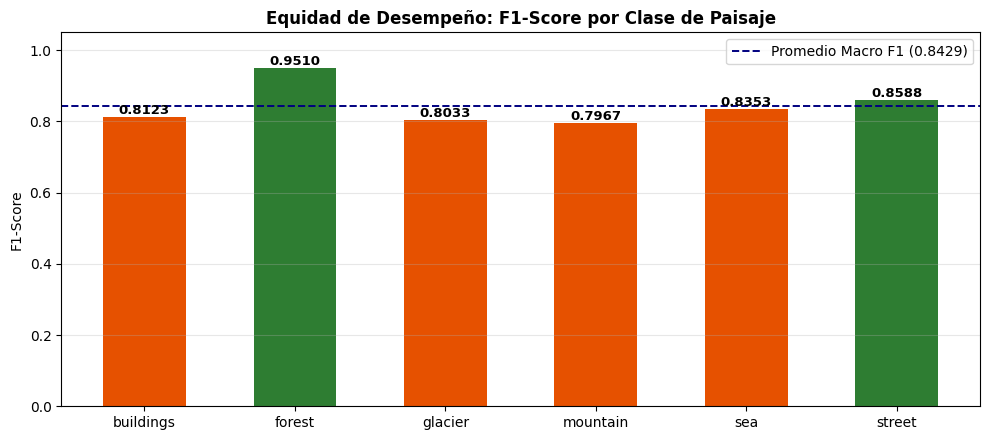

In [ ]:
# ==============================================================================
# AUDITORÍA DE SESGOS DE PREDICCIÓN, PARES DE CONFUSIÓN Y ALTA CONFIANZA
# ==============================================================================
sesgos_res = auditar_sesgos_modelo(
    ctx["mejor_modelo"], ctx["test_ds"], ctx["class_names"],
    umbral_confianza=0.80, plot=True, verbose=True
)

### 8.3 Diagnóstico de Sesgos, Implicancias Éticas y Estrategias de Mitigación
1. **Sesgo de datos vs. sesgo visual:** La Etapa 2 demostró un dataset equilibrado (`Ratio Max/Min = 1.15x` en entrenamiento y `1.14x` en validación), descartando sesgos severos por desbalance de muestras. Las brechas de `F1-Score` entre clases (donde `forest` alcanza **`0.9510`** y `street` **`0.8588`**, mientras `glacier` obtiene **`0.8033`** y `mountain` **`0.7967`**) se deben a **ambigüedad visual compartida**: el **65.8% de los `474` errores en Test (`312` casos)** se concentra en `glacier <-> mountain` (`79 + 55 = 134`), `buildings -> street` (`81`) y las confusiones costeras/montañosas entre `sea`, `mountain` y `glacier` (`37 + 34 + 26 = 97`).
2. **Riesgo de sobreconfianza y ética inmobiliaria:** Del total de **`474` errores en Test (`15.80%`)**, **`158` errores (`33.3%`)** ocurrieron con **confianza `>= 80%`**. En una plataforma de tasación inmobiliaria con drones, automatizar decisiones sin control podría clasificar erróneamente una edificación urbana (`buildings` vs. `street`) o un entorno natural (`glacier` vs. `mountain`), induciendo **tasaciones sesgadas o injustas** y falta de transparencia ante reclamos.
3. **Medidas concretas de mitigación:**
   * **Revisión humana (*Human-in-the-Loop*):** Derivar a validación manual toda imagen con confianza `< 0.80` (como los casos ambiguos detectados en Grad-CAM) o cuyas dos clases más probables (`top-2`) sean pares conflictivos (`buildings/street` o `glacier/mountain`).
   * **Aumento de datos fotométrico:** Incorporar variaciones leves de brillo y contraste (`RandomContrast`, `RandomBrightness`) para reducir la dependencia de tonos globales de color y neblina.
   * **Evolución a clasificación *Multi-label*:** Permitir múltiples etiquetas simultáneas en fotografías aéreas donde coexisten edificios y calles o montañas y mar.
   * **Monitoreo por clase en producción:** Auditar periódicamente el *Recall* de `buildings` (`0.7529`) y el *F1-Score* de `mountain` (`0.7967`) antes de desplegar nuevas versiones.

---
## 9. Conclusiones Finales y Evaluación Crítica del Pipeline Integrado

### 9.1 Selección Integral del Modelo Final Recomendado
Se recomienda la **CNN Regularizada y Optimizada (`1. LR Fino`: `Data Augmentation + Dropout 0.5 + Early Stopping`, `Dense(128)`, `lr = 0.0005`)** como solución definitiva para la clasificación automática de entornos inmobiliarios con drones, integrando los cuatro pilares exigidos:
1. **Desempeño y Generalización:** Alcanza **`84.20%` de Accuracy**, **`0.8415` de F1-Score**, **`Val_Loss = 0.4608`** y **`ROC-AUC Macro = 0.9770`**, superando al **MLP Base (Ev. 1: `54.37%`)** por **+29.83 puntos porcentuales** y a la **CNN sin regularizar (Ev. 2: `78.47%`)** en **+5.73 puntos**, reduciendo la brecha de sobreajuste de **`20.22%` a `1.42%`**.
2. **Eficiencia Computacional y Memoria:** Mantiene exactamente **`4,829,126` parámetros** (**44.2% menos** que los `8.65M` del MLP Base) con un tiempo de entrenamiento acotado de **`181.47 s` (~3.0 min, `10.08 s/época`)** en GPU T4, logrando un equilibrio óptimo tanto para inferencia en servidor/nube como para despliegues ligeros en dispositivos *Edge*.
3. **Explicabilidad (XAI):** Permite auditoría espacial directa mediante **Grad-CAM** sobre `Conv_3`, confirmando foco en rasgos semánticos reales del paisaje (a diferencia de la "caja negra" 1D del MLP) e identificando visualmente escenas con baja confianza por neblina o oleaje.
4. **Responsabilidad Ética:** Cuantifica explícitamente los límites del modelo (pares conflictivos y `33.3%` de errores con confianza `>= 80%`) e incorpora reglas concretas de mitigación *Human-in-the-Loop* antes de impactar tasaciones comerciales.

### 9.2 Evaluación Crítica del Pipeline Integrado (Fortalezas, Limitaciones y Mejoras Futuras)
* **Fortalezas del Pipeline desarrollado:**
  * Arquitectura **100% modular en 9 etapas** orquestada de extremo a extremo (`ejecutar_pipeline_completo()`), reproducible (`SEED = 29`) y con **persistencia incremental** (`.csv`, `.json` y `.keras`) resistente a desconexiones de Colab/Kaggle.
  * Selección de modelos basada en **`Val_Loss`** (libre de fuga de datos del conjunto `test_ds`) y limpieza activa de memoria GPU (`clear_session()` + `gc.collect()`).
* **Limitaciones y riesgos identificados:**
  * Entrenar una CNN desde cero limita la discriminación fina en clases visualmente solapadas (`glacier` vs. `mountain` y fachadas urbanas `buildings` vs. `street`) y depende de GPU para ejecutar los 18 entrenamientos completos en tiempos razonables.
  * Leve no-determinismo de operaciones convolucionales en GPU (`cuDNN`) entre corridas consecutivas (`±0.5%` en Test Accuracy).
  * Etiquetado excluyente (*single-label*) que simplifica escenas urbanas o costeras compuestas.
* **Propuestas de mejora para futuras iteraciones:**
  1. **Transfer Learning (*Fine-Tuning*):** Reemplazar el extractor convolucional desde cero por arquitecturas preentrenadas (*EfficientNetB0* o *ResNet50* en ImageNet) para elevar el F1 en `glacier`, `mountain` y `buildings` por encima de `0.90`.
  2. **Calibración de probabilidades (*Temperature Scaling*):** Reducir la tasa de errores con confianza `>= 80%` para hacer más confiable el umbral *Human-in-the-Loop*.
  3. **Búsqueda de hiperparámetros ampliada:** Integrar *Random Search* o *Optuna* junto con *Cosine Decay* / *ReduceLROnPlateau* para el *learning rate*.
  4. **Monitoreo de *Data Drift*:** Registrar periódicamente cambios en la distribución de imágenes capturadas por nuevos modelos de drones o distintas estaciones climáticas.